### Generic functions

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


#### Get params

In [44]:
# Bad version

def analyze_signal(t_us, y):
    t = (t_us - t_us[0])
    dt = t[1] - t[0]

    offset = float(np.mean(y))
    A = float((np.max(y) - np.min(y)) / 2)

    Y = np.fft.rfft(y - offset)
    freqs = np.fft.rfftfreq(len(y), dt)

    idx = np.argmax(np.abs(Y[1:])) + 1
    f0 = float(freqs[idx])
    phi_cos = float(np.angle(Y[idx]))   # phase for cos-convention

    # Return in the EXACT names your generator expects
    return {
        "f0": f0,
        "A": A,
        "offset": offset,
        "phi0": phi_cos,   # keep as-is; decide convention in the generator
    }

In [45]:
# Cool, hard version

def bestfit_fourier_params2(
    t_raw,
    y,
    N=25,
    time_unit="auto",          # "auto", "s", "us", "ms", or float scale factor (e.g. 1e-6)
    center_time=False,    # change
    robust=True,
    max_nfev=400,
    return_fit=True,    # put True to receive the fitted function too
    plot=True,
):
    """
    Fit a Fourier series to data, optimizing only frequency f and time-shift t0,
    while solving Fourier coefficients linearly for each (f, t0).
    
    Returns a params dict compatible with your waveform generators:
        params = {"f0": f_opt, "A": A_opt, "offset": offset_opt, "phi0": 0.0, ...}

    Notes:
    - This fit is a *general Fourier series* (cos+sin), not specifically a square.
      So phi0 is not uniquely defined; we return phi0=0 and provide t0 + beta.
    - If you want a square/triangle/sawtooth with your param-style, use f0 + t0.
    """

    # ----------------------------
    # 1) time conversion to seconds
    # ----------------------------
    t_raw = np.asarray(t_raw, dtype=float)
    y = np.asarray(y, dtype=float)

    t = t_raw.copy()

    if isinstance(time_unit, (int, float)):          # user gives scale factor to seconds
        t = t * float(time_unit)
    else:
        tu = str(time_unit).lower()
        if tu == "s":
            pass
        elif tu == "us":
            t = t * 1e-6
        elif tu == "ms":
            t = t * 1e-3
        elif tu == "auto":
            # heuristic: if big numbers -> assume microseconds
            if np.nanmax(t) > 1000:
                t = t * 1e-6
        else:
            raise ValueError("time_unit must be 'auto', 's', 'us', 'ms', or a numeric scale factor")

    if center_time:
        t = t - np.nanmin(t)

    # ----------------------------
    # 2) initial frequency guess via FFT
    # ----------------------------
    dt = np.median(np.diff(t))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Time array must be increasing and contain at least 2 points.")

    y_detr = y - np.mean(y)
    Y = np.fft.rfft(y_detr)
    freqs = np.fft.rfftfreq(len(y_detr), d=dt)

    k0 = 1
    k_peak = k0 + np.argmax(np.abs(Y[k0:]))
    f0_guess = float(freqs[k_peak]) if freqs[k_peak] > 0 else 1.0

    # ----------------------------
    # 3) design matrix + linear solve
    # ----------------------------
    def design_matrix(tt, omega, t0):
        tau = tt - t0
        cols = [np.ones_like(tt)]
        for n in range(1, N + 1):
            cols.append(np.cos(n * omega * tau))
            cols.append(np.sin(n * omega * tau))
        return np.column_stack(cols)

    def fit_linear_coeffs(tt, yy, omega, t0):
        X = design_matrix(tt, omega, t0)
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        yhat = X @ beta
        return beta, yhat

    def residuals_nonlinear(p):
        log_f, t0 = p
        f = np.exp(log_f)
        omega = 2 * np.pi * f
        _, yhat = fit_linear_coeffs(t, y, omega, t0)
        return (yhat - y)

    # ----------------------------
    # 4) nonlinear fit (log_f, t0)
    # ----------------------------
    p0 = np.array([np.log(f0_guess), 0.0])

    ls_kwargs = dict(
        fun=residuals_nonlinear,
        x0=p0,
        max_nfev=max_nfev,
    )
    if robust:
        ls_kwargs.update(
            loss="soft_l1",
            f_scale=float(np.std(y)) if np.std(y) > 0 else 1.0,
        )

    res = least_squares(**ls_kwargs)

    log_f_opt, t0_opt = res.x
    f_opt = float(np.exp(log_f_opt))
    omega_opt = 2 * np.pi * f_opt

    beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, float(t0_opt))

    # ----------------------------
    # 5) readable params (like your previous ones)
    # ----------------------------
    offset_opt = float(beta_opt[0])
    A_pp = float(np.max(yhat_opt) - np.min(yhat_opt))
    A_opt = 0.5 * A_pp

    # For "phi0": not uniquely meaningful for a general Fourier fit,
    # but if you want to use your sin-based generators, the *time shift* is the key.
    # You can map t0 into an equivalent fundamental phase shift:
    phi0_equiv = float(-omega_opt * t0_opt)  # so sin(ω(t - t0)) = sin(ωt + phi0_equiv)

    params = {
        "f0": f_opt,
        "A": A_opt,
        "offset": offset_opt,
        "phi0": phi0_equiv,   # usable with your sin-based series
        # extras (often useful)
        "t0": float(t0_opt),
        "N": int(N),
        "beta": beta_opt,     # [c0, a1,b1,a2,b2,...]
        "rmse": float(np.sqrt(np.mean((yhat_opt - y) ** 2))),
        "success": bool(res.success),
        "cost": float(res.cost),
    }

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(t, y, linewidth=1.5, label="data")
        plt.plot(t, yhat_opt, linewidth=2.5, label="best-fit Fourier")
        plt.grid(True, alpha=0.3)
        plt.xlabel("t (s)")
        plt.ylabel("y")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if return_fit:
        return params, t, yhat_opt
    return params


In [46]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

def bestfit_fourier_params3(
    t_raw,
    y,
    N=25,
    time_unit="auto",
    center_time=True,
    robust=True,
    max_nfev=400,
    return_fit=False,
    plot=False,
):
    """
    Fit a general Fourier series to data, optimizing frequency f0 and phase phi0.
    Returns params compatible with sin(ωt + phi0)-based generators.
    """

    # ----------------------------
    # 1) time conversion to seconds
    # ----------------------------
    t_raw = np.asarray(t_raw, dtype=float)
    y = np.asarray(y, dtype=float)

    t = t_raw.copy()

    if isinstance(time_unit, (int, float)):
        t = t * float(time_unit)
    else:
        tu = str(time_unit).lower()
        if tu == "s":
            pass
        elif tu == "us":
            t = t * 1e-6
        elif tu == "ms":
            t = t * 1e-3
        elif tu == "auto":
            if np.nanmax(t) > 1000:
                t = t * 1e-6
        else:
            raise ValueError("Invalid time_unit")

    if center_time:
        t = t - np.nanmin(t)

    # ----------------------------
    # 2) initial frequency guess via FFT
    # ----------------------------
    dt = np.median(np.diff(t))
    y_detr = y - np.mean(y)

    Y = np.fft.rfft(y_detr)
    freqs = np.fft.rfftfreq(len(y_detr), d=dt)

    k_peak = 1 + np.argmax(np.abs(Y[1:]))
    f0_guess = float(freqs[k_peak]) if freqs[k_peak] > 0 else 1.0

    # ----------------------------
    # 3) design matrix (phi0 version)
    # ----------------------------
    def design_matrix(tt, omega, phi0):
        cols = [np.ones_like(tt)]
        for n in range(1, N + 1):
            cols.append(np.cos(n * (omega * tt + phi0)))
            cols.append(np.sin(n * (omega * tt + phi0)))
        return np.column_stack(cols)

    def fit_linear_coeffs(tt, yy, omega, phi0):
        X = design_matrix(tt, omega, phi0)
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        return beta, X @ beta

    def residuals_nonlinear(p):
        log_f, phi0 = p
        f = np.exp(log_f)
        omega = 2 * np.pi * f
        _, yhat = fit_linear_coeffs(t, y, omega, phi0)
        return yhat - y

    # ----------------------------
    # 4) nonlinear fit (log_f, phi0)
    # ----------------------------
    p0 = np.array([np.log(f0_guess), 0.0])

    ls_kwargs = dict(
        fun=residuals_nonlinear,
        x0=p0,
        max_nfev=max_nfev,
    )

    if robust:
        ls_kwargs.update(
            loss="soft_l1",
            f_scale=float(np.std(y)) if np.std(y) > 0 else 1.0,
        )

    res = least_squares(**ls_kwargs)

    log_f_opt, phi0_opt = res.x
    f_opt = float(np.exp(log_f_opt))
    omega_opt = 2 * np.pi * f_opt

    beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, phi0_opt)

    # ----------------------------
    # 5) readable params
    # ----------------------------
    offset_opt = float(beta_opt[0])
    A_pp = float(np.max(yhat_opt) - np.min(yhat_opt))
    A_opt = 0.5 * A_pp

    params = {
        "f0": f_opt,
        "A": A_opt,
        "offset": offset_opt,
        "phi0": float(phi0_opt),   # 👈 now the primary phase parameter
        "N": int(N),
        "beta": beta_opt,
        "rmse": float(np.sqrt(np.mean((yhat_opt - y) ** 2))),
        "success": bool(res.success),
        "cost": float(res.cost),
    }

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(t, y, label="data", lw=1.5)
        plt.plot(t, yhat_opt, label="best-fit Fourier", lw=2.5)
        plt.grid(True, alpha=0.3)
        plt.xlabel("t (s)")
        plt.ylabel("y")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if return_fit:
        return params, t, yhat_opt

    return params


if output without fitting, ony put params as return  
if output with fit, i'm return 3 objects, so pu them in: params, _, _  
else gives error, bc params is a tuple  

#### Fit function

In [47]:
def square_wave_fourier(t, N_harm=50, **params):
    """
    Onda quadra tramite serie di Fourier

    params can contain:
        f0, A, offset, phi0
    """
    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    phi0   = params.get("phi0", 0.0)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    for k in range(1, N_harm + 1, 2):
        w += (4 / (np.pi * k)) * np.sin(k * (omega * t + phi0))

    return offset + A * w


In [48]:
import numpy as np

def square_wave_fourier2(t, N_odd=25, **params):
    """
    Ideal 50% duty-cycle square wave via Fourier series.

    params can contain:
        f0     : fundamental frequency (Hz)
        A      : amplitude (≈ peak-to-peak / 2)
        offset : vertical offset
        t0     : time shift (seconds)
    """

    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    t0     = params.get("t0", 0.0)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    # Use N_odd odd harmonics: k = 1,3,5,...,(2*N_odd-1)
    for k in range(1, N_odd + 1, 2):
        w += (4 / (np.pi * k)) * np.sin(k * omega * (t - t0))

    return offset + A * w


In [49]:
def triangle_wave_fourier(t, N_harm=50, **params):
    """
    Onda triangolare tramite serie di Fourier (forma seno)

    params can contain:
        f0, A, offset, phi0
    """
    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    phi0   = params.get("phi0", 0.0)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    # odd harmonics with alternating sign and 1/k^2 decay
    for k in range(1, N_harm + 1, 2):
        sign = (-1)**((k - 1)//2)
        w += sign * (8 / (np.pi**2 * k**2)) * np.sin(k * (omega * t + phi0))

    return offset + A * w

In [50]:
def shark_fin_wave_fourier(t, N_harm=50, direction="rising", **params):
    """
    'Pinna di squalo' (sawtooth/ramp) via Fourier series.

    params can contain:
        f0, A, offset, phi0

    direction:
        "rising"  -> slow rise then sudden drop (classic rising sawtooth)
        "falling" -> sudden rise then slow fall
    """
    f0     = params.get("f0", 1.0)
    A      = params.get("A", 1.0)
    offset = params.get("offset", 0.0)
    phi0   = params.get("phi0", 0.0)

    omega = 2 * np.pi * f0
    w = np.zeros_like(t, dtype=float)

    # Sawtooth Fourier series uses ALL harmonics (not only odd)
    # Base (rising) sawtooth in [-1, 1]:
    #   w(t) = (2/pi) * sum_{n=1..∞} (-1)^{n+1} (1/n) sin(n(ωt+phi0))
    for n in range(1, N_harm + 1):
        w += ((-1)**(n + 1) / n) * np.sin(n * (omega * t + phi0))

    w *= (2 / np.pi)

    if direction.lower() == "falling":
        w = -w

    return offset + A * w


In [51]:
def upload(dir, file):
    path=(dir+file)
    x,y=np.loadtxt(path,unpack=True)
    # turn into seconds
    x = (x-x[0])* 1e-6

    params = analyze_signal(x, y)

    return x,y, params

### Try generic

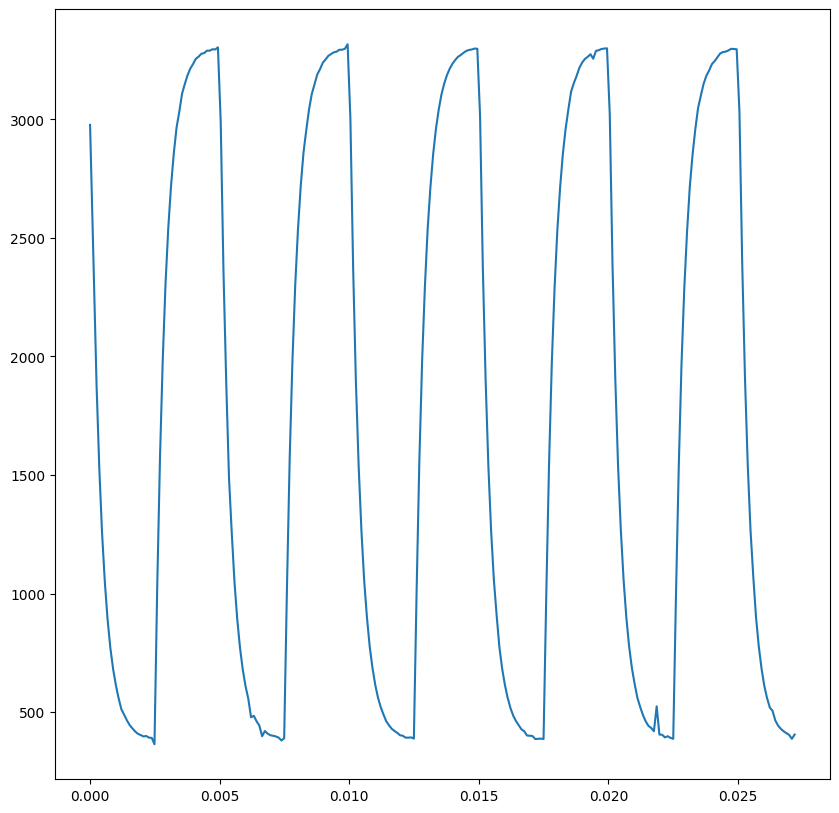

In [52]:
# Plot a file

Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'
NomeFile = 'integratore_3.txt'

t1,y1, params = upload(Directory, NomeFile)
plt.figure(figsize=(10,10))
plt.plot(t1,y1)   # plotta in secondi, non microsecondi

In [53]:
# Do a Fourier reconstruction, just once, to find good params

def fourier_series(t,y, params):
    '''In caso volessi modificare i params, li dò separati'''

    plt.figure(figsize=(20, 20))

    plt.plot(t, y, linewidth=2.0, label=f"Experimental data")
    yf = square_wave_fourier(t1, N_harm=51, **params)
    plt.plot(t, yf, label='Fourier')

    plt.xlabel("t (s)")
    plt.ylabel("signal")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return params

In [54]:
def multiple_fourier_series(t, y, params, N_list=(1, 3, 11, 21, 51)):
    """
    One figure per N_harm in N_list.
    params is a dict with keys: f0, A, offset, phi0 (as used by square_wave_fourier).
    """
    for N_harm in N_list:
        plt.figure(figsize=(12, 5))
        plt.plot(t, y, linewidth=2.0, label="Experimental data")

        yf = square_wave_fourier2(t, N_harm=N_harm, **params)   # hese is 2
        plt.plot(t, yf, linewidth=2.0, label=f"Fourier (N_harm={N_harm})")

        plt.xlabel("t (s)")
        plt.ylabel("signal")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

    return params

In [55]:
def multiple_fourier_series_tr(t, y, params, N_list=(1, 3, 11, 21, 51)):
    """
    One figure per N_harm in N_list.
    params is a dict with keys: f0, A, offset, phi0 (as used by square_wave_fourier).
    """
    for N_harm in N_list:
        plt.figure(figsize=(12, 5))
        plt.plot(t, y, linewidth=2.0, label="Experimental data")

        yf = triangle_wave_fourier(t, N_harm=N_harm, **params)
        plt.plot(t, yf, linewidth=2.0, label=f"Fourier (N_harm={N_harm})")

        plt.xlabel("t (s)")
        plt.ylabel("signal")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()
    
    return params

can i make a single function to recosntruct square and triangle???

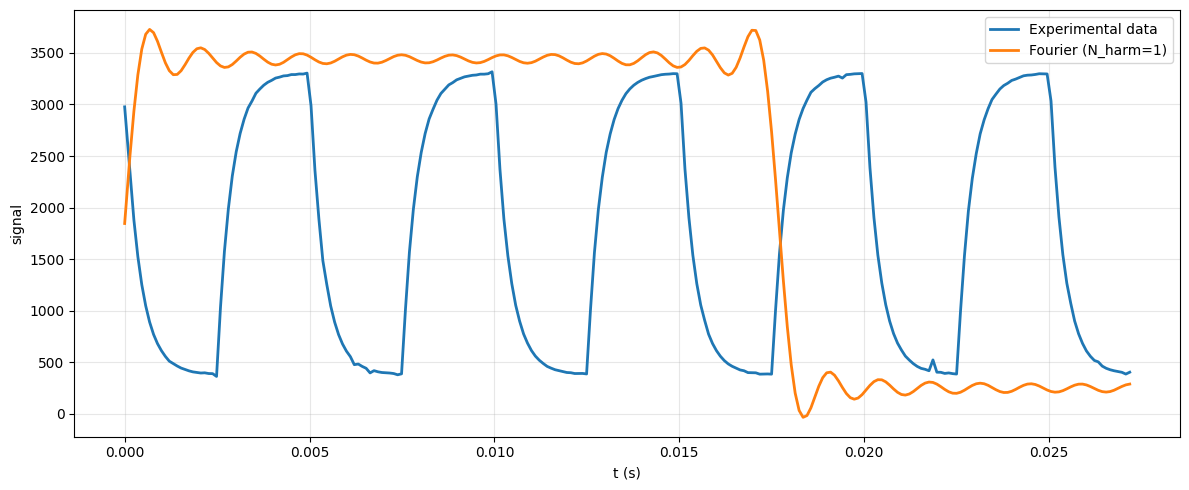

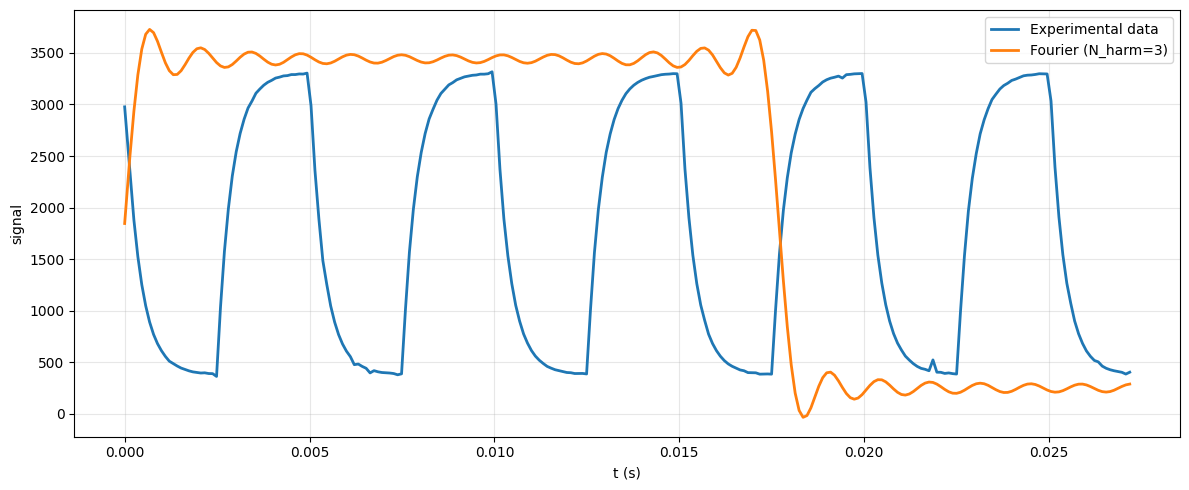

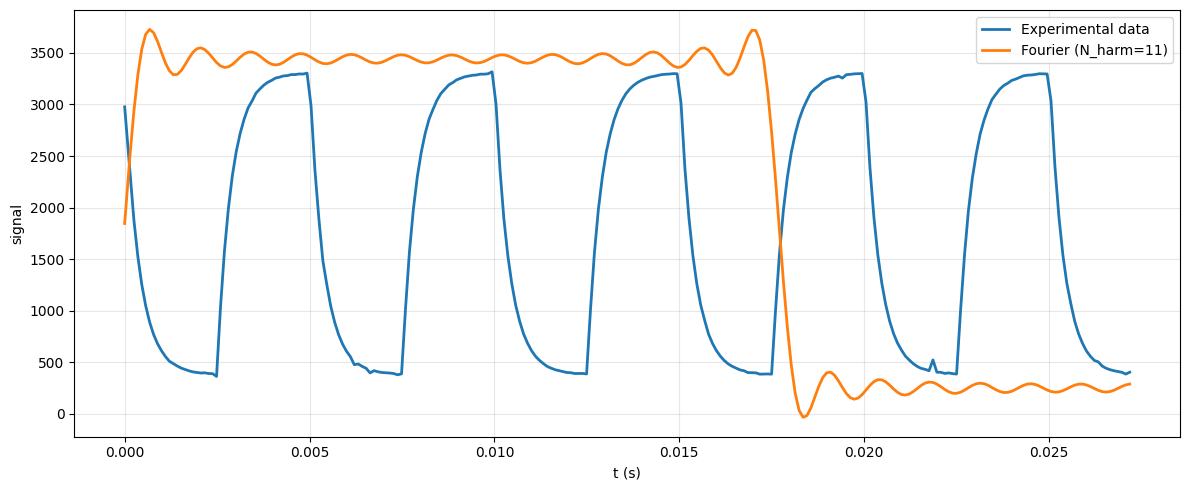

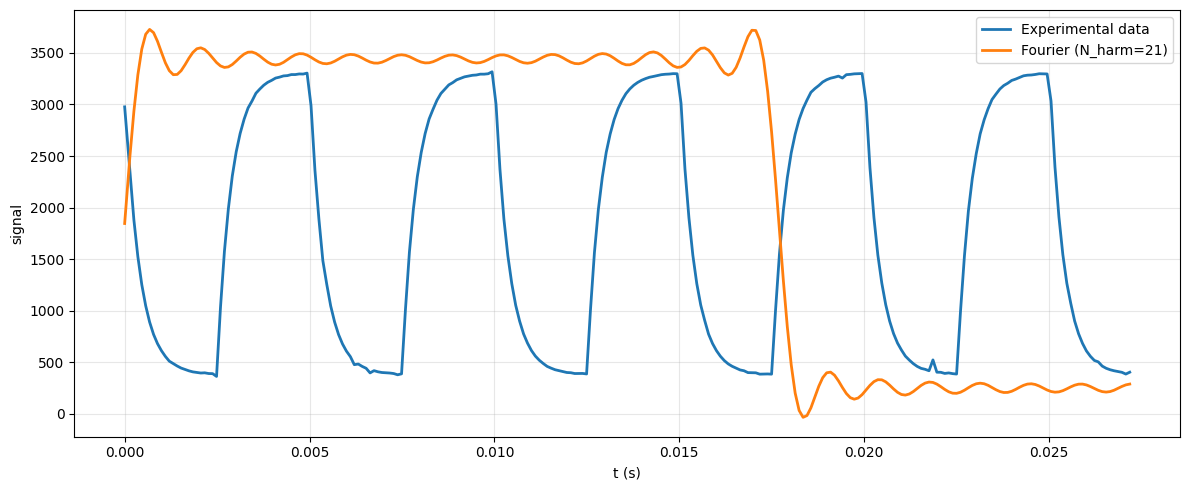

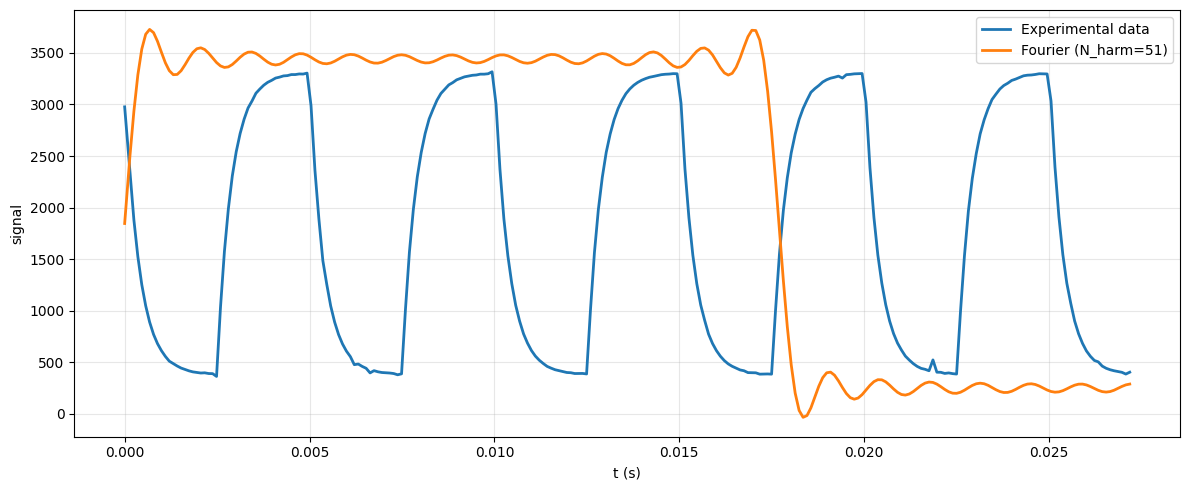

{'f0': 28.259064357714447,
 'A': 1595.2055808616535,
 'offset': 1846.4872060542261,
 'phi0': 0.1}

In [56]:
params_new = {'f0': 126.53180609676548,
 'A': 925.0608240482802,
 'offset': 1296.4522182087974,
 'phi0': 89328.52320387364,
}

params_new2 = {'f0': 28.259064357714447, 'A': 1595.2055808616535, 'offset': 1846.4872060542261, 'phi0': 0.1}


multiple_fourier_series(t1,y1, params_new2)

# Problem with OFFSET !!!

In [57]:
params

{'f0': 136.58216783216784,
 'A': 1476.5,
 'offset': 1765.37890625,
 'phi0': 2.6004037466411156}

### 1 - Simulazione onda quadra e triangolare

In [58]:
# Params per simulazione

N_list=(1, 2, 3, 4, 100)

params_sim = {
        'f0':1,
        'A': 1,
        'offset':0,
        'phi0':0
}

T = 1/params_sim['f0']
t = np.linspace(0, 5*T, 4000)

/tmp/ipykernel_46502/3626036856.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


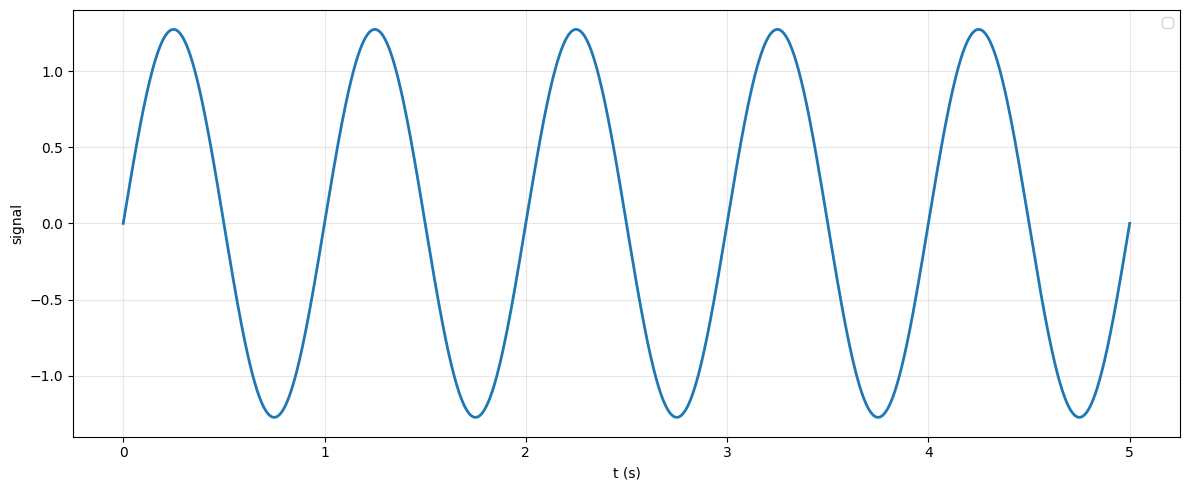

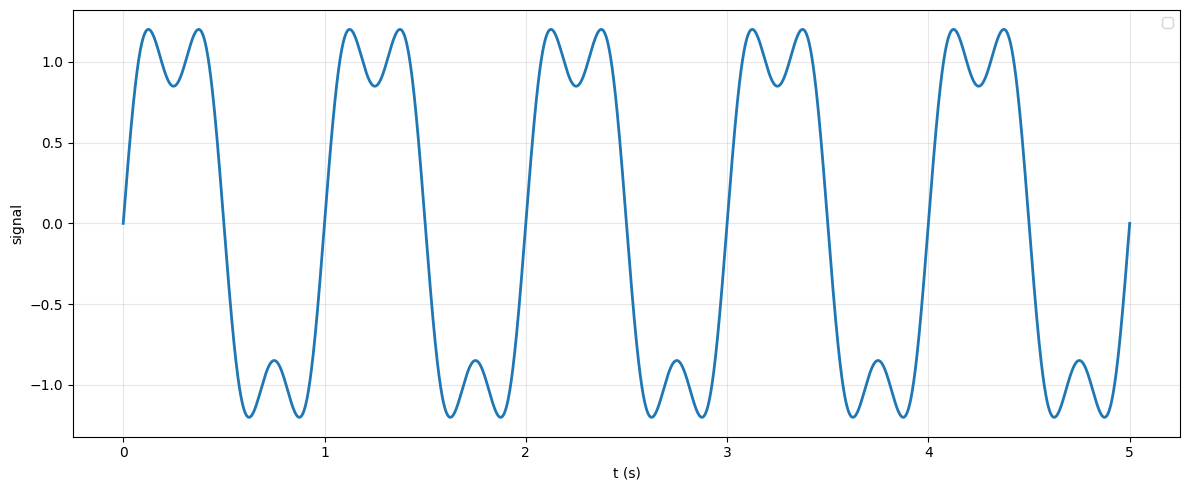

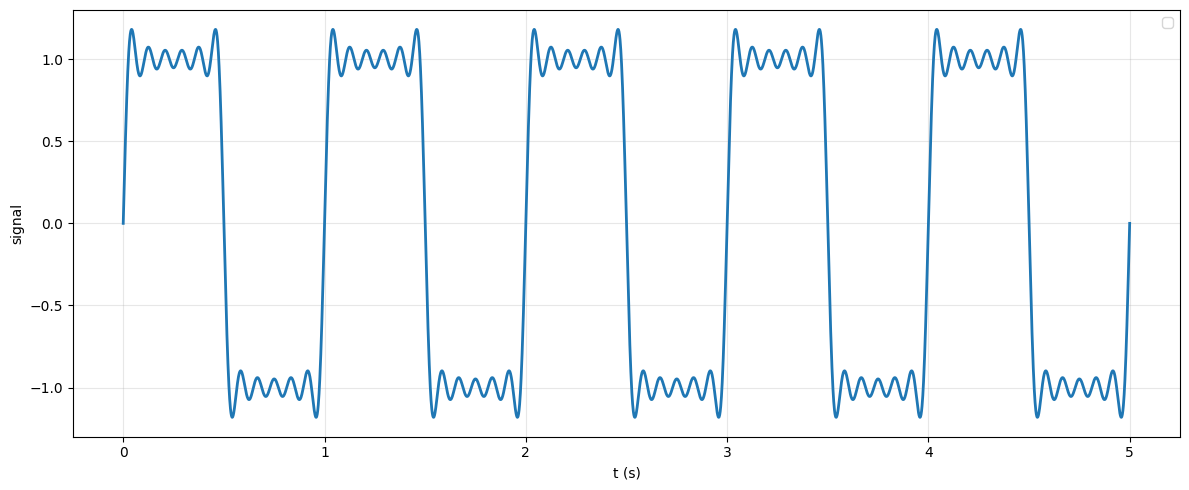

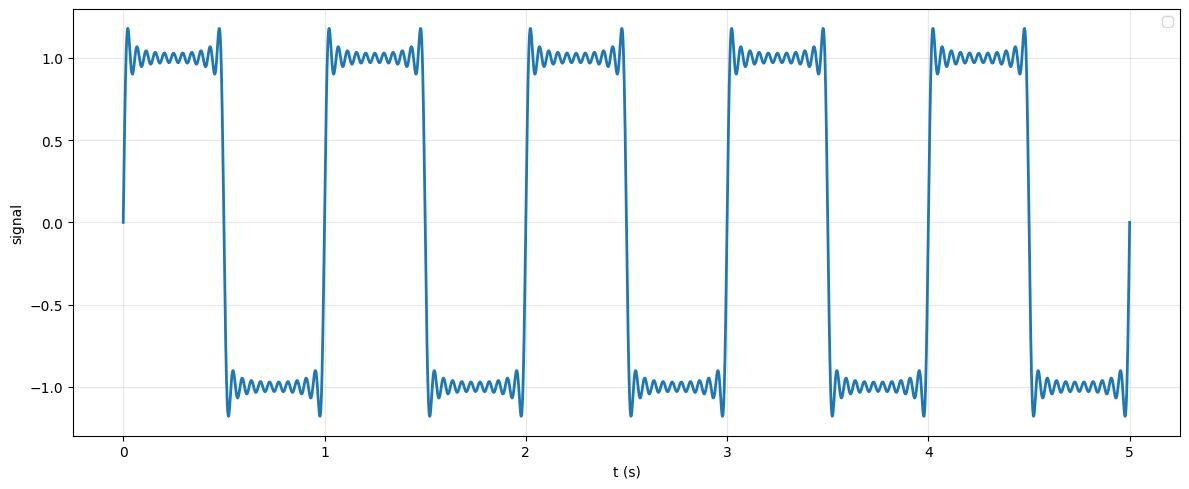

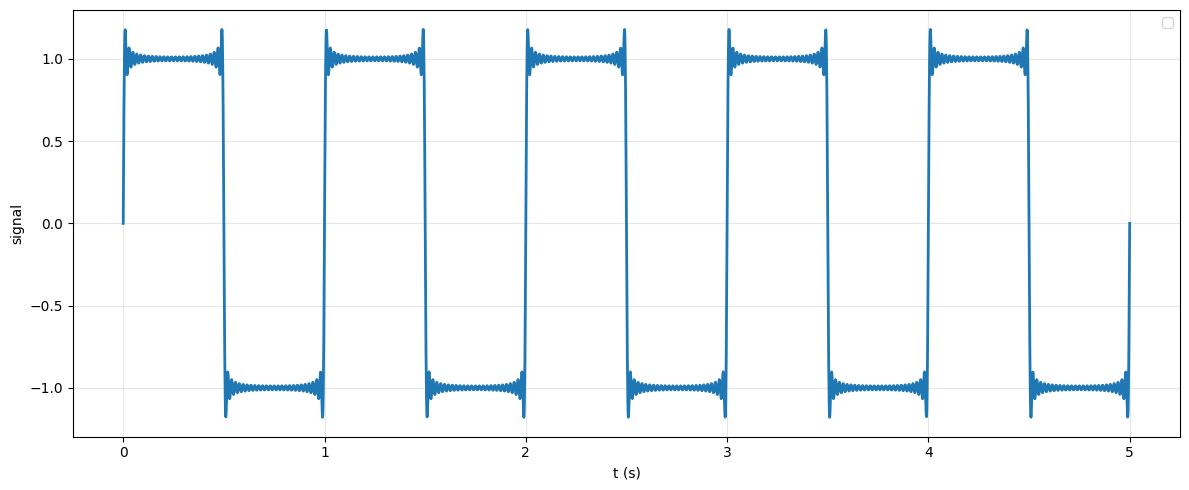

In [59]:
# Square wave

N_list=(1, 3, 11, 21, 51)


for N_harm in N_list:
        y = square_wave_fourier(t, N_harm=N_harm, **params_sim)

        plt.figure(figsize=(12, 5))
        plt.plot(t, y, linewidth=2.0, )

        plt.xlabel("t (s)")
        plt.ylabel("signal")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

/tmp/ipykernel_46502/2804888040.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


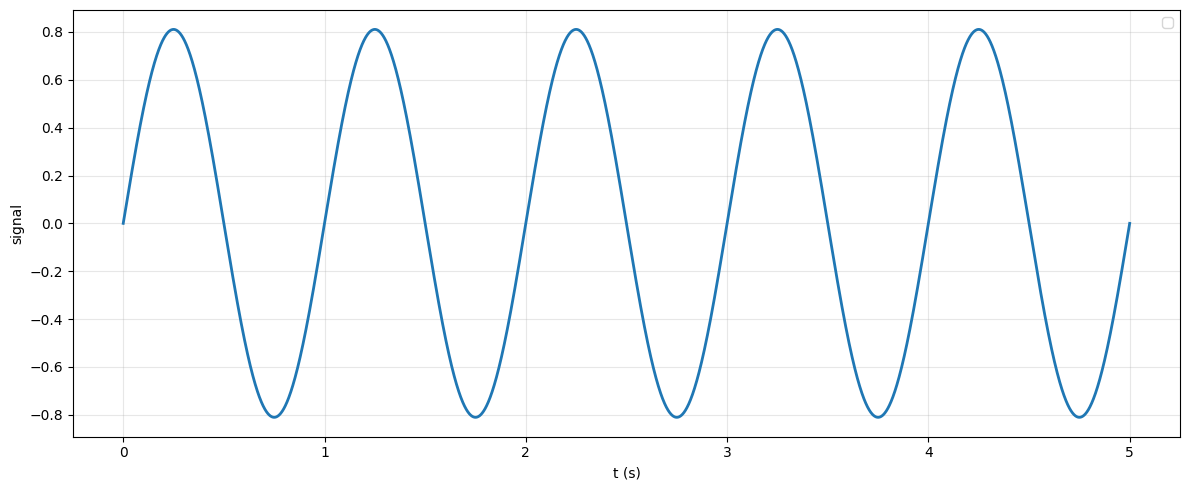

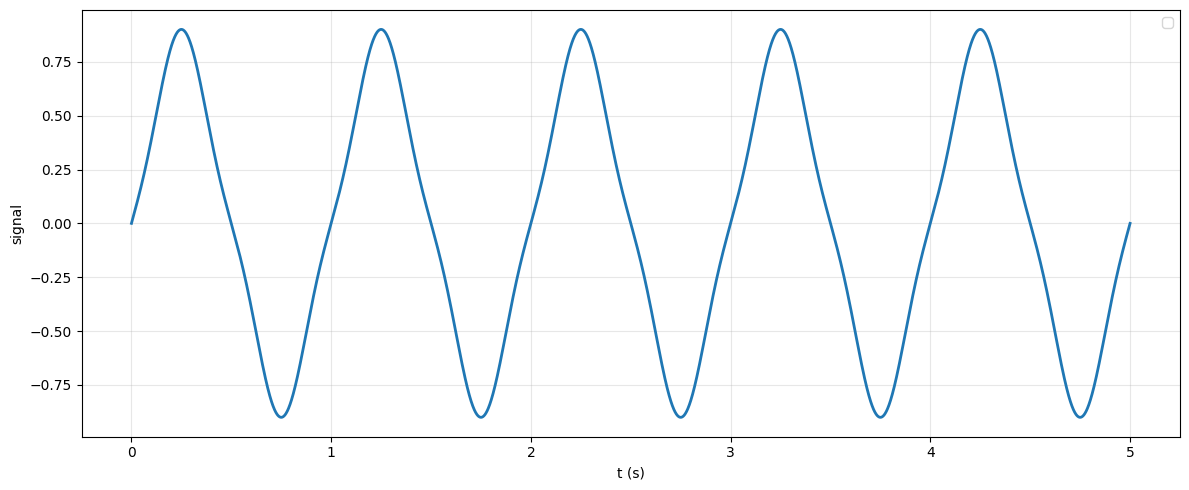

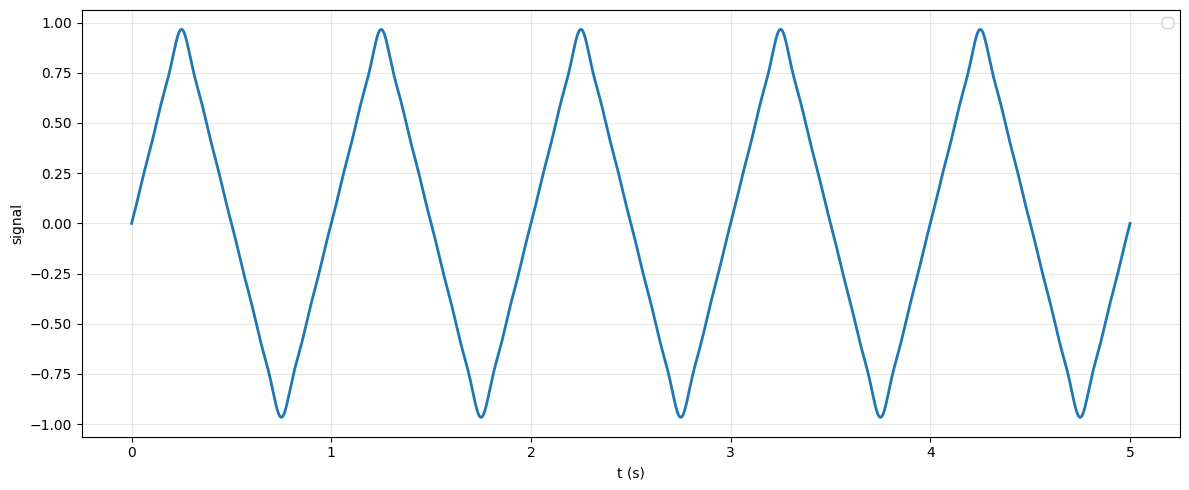

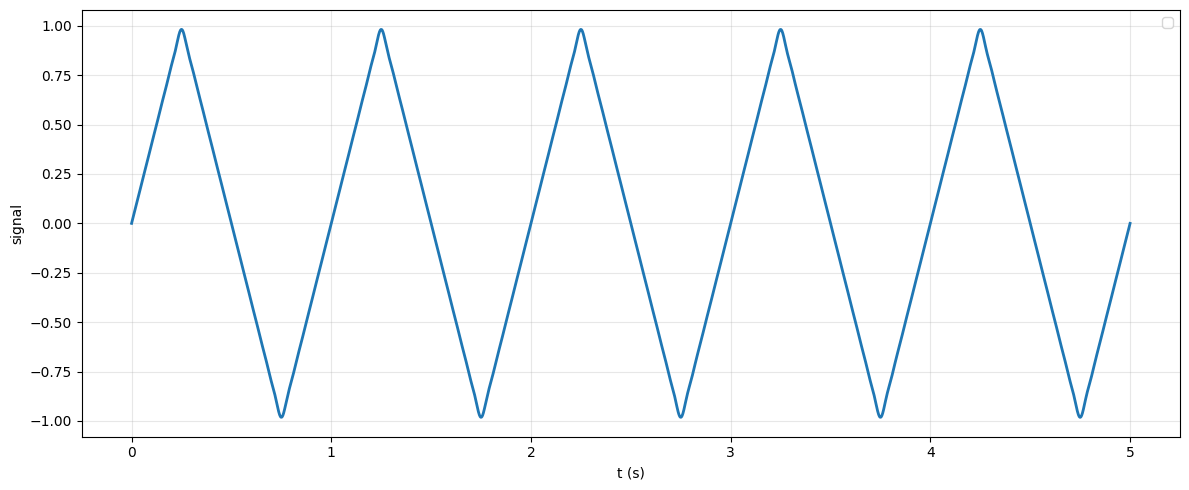

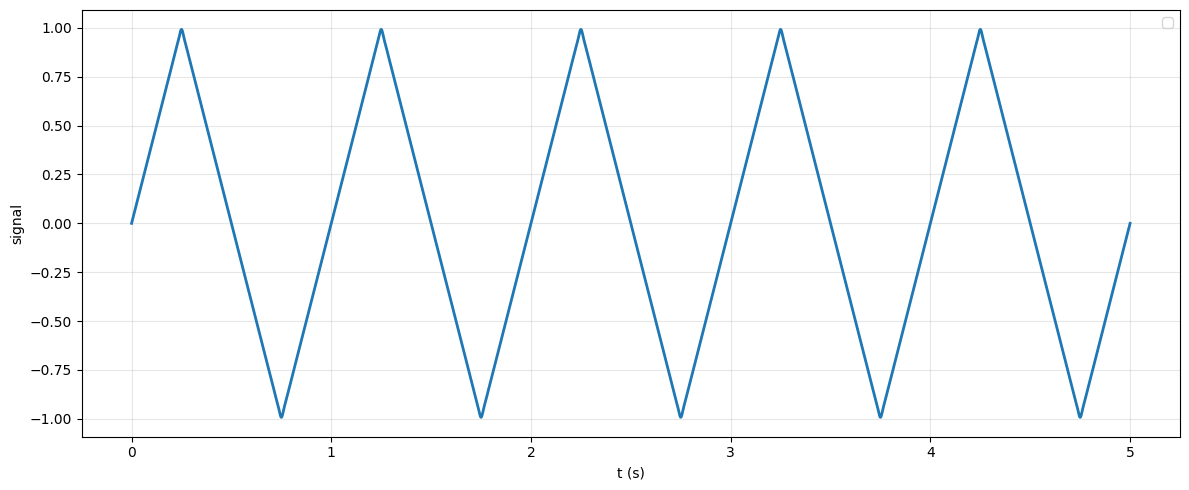

In [60]:
# Triangle wave

for N_harm in N_list:
        y = triangle_wave_fourier(t, N_harm=N_harm, **params_sim)

        plt.figure(figsize=(12, 5))
        plt.plot(t, y, linewidth=2.0)

        plt.xlabel("t (s)")
        plt.ylabel("signal")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

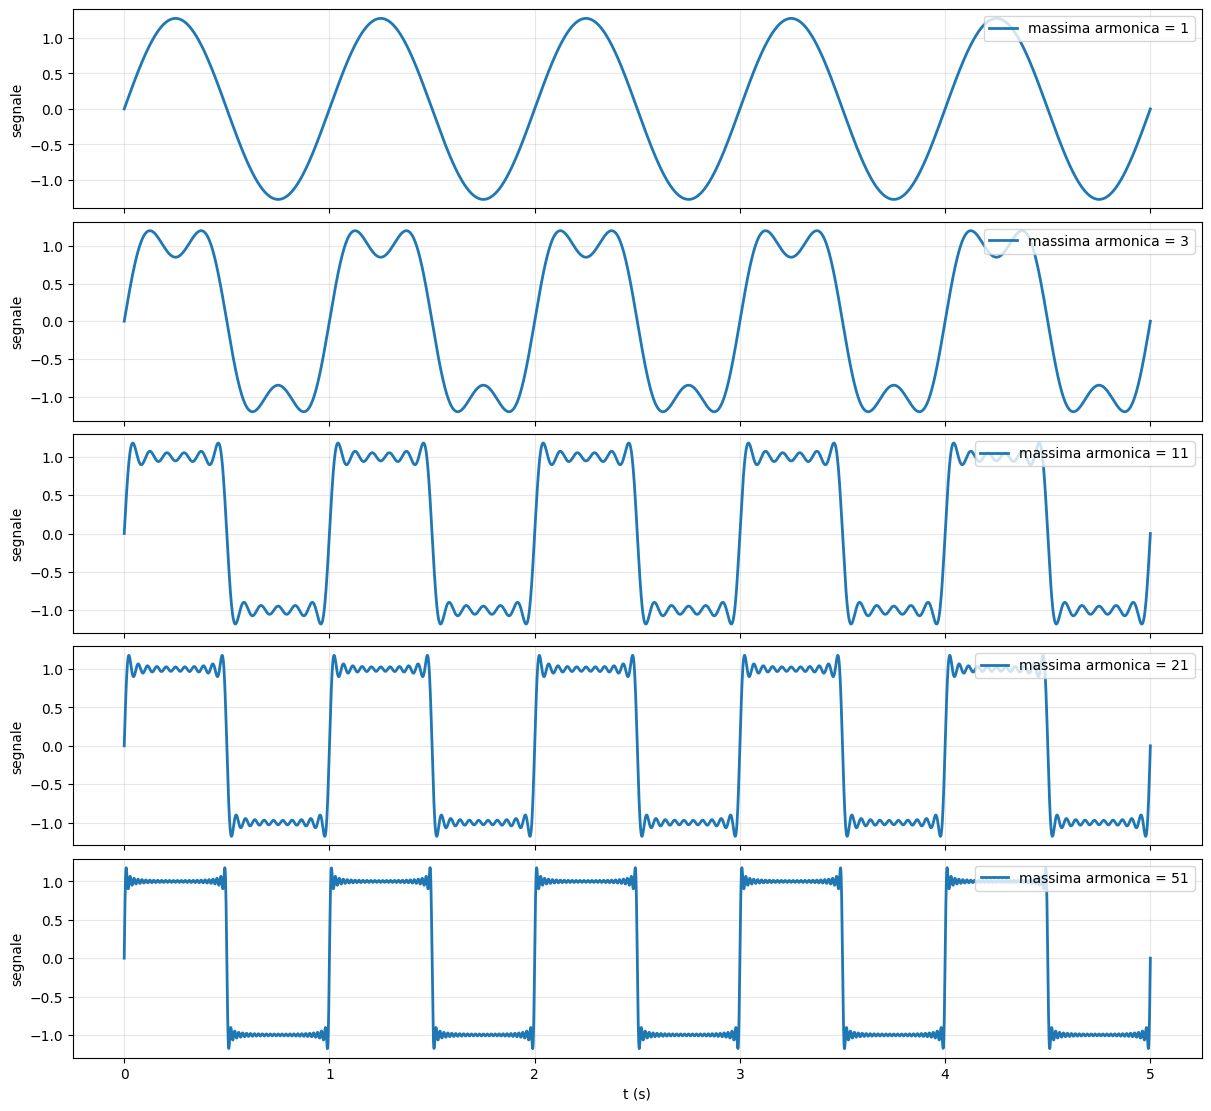

In [61]:
# Square wave: una riga per ogni N_harm, con asse x condiviso
fig, axes = plt.subplots(
    nrows=len(N_list),
    ncols=1,
    sharex=True,
    figsize=(12, 2.2 * len(N_list)),
    constrained_layout=True
)

# Se N_list ha un solo elemento, axes non è una lista: normalizziamo
if len(N_list) == 1:
    axes = [axes]

for ax, N_harm in zip(axes, N_list):
    y = square_wave_fourier(t, N_harm=N_harm, **params_sim)

    ax.plot(t, y, linewidth=2.0, label=f"massima armonica = {N_harm}")
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("t (s)")
plt.show()


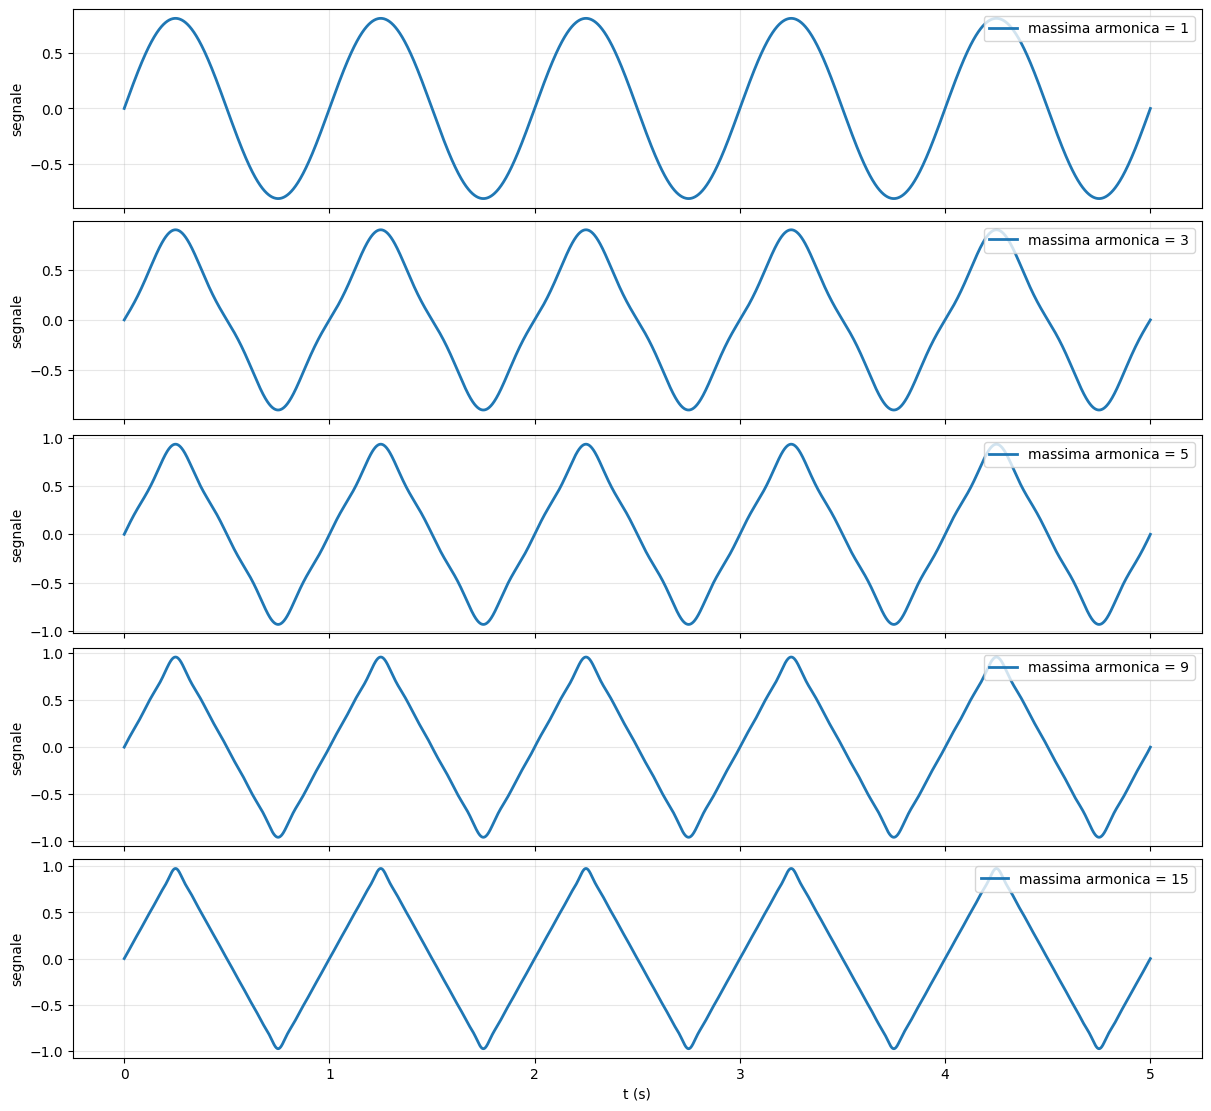

In [62]:

N_list=(1, 3, 5, 9, 15)

# Square wave: una riga per ogni N_harm, con asse x condiviso
fig, axes = plt.subplots(
    nrows=len(N_list),
    ncols=1,
    sharex=True,
    figsize=(12, 2.2 * len(N_list)),
    constrained_layout=True
)

# Se N_list ha un solo elemento, axes non è una lista: normalizziamo
if len(N_list) == 1:
    axes = [axes]

for ax, N_harm in zip(axes, N_list):
    y = triangle_wave_fourier(t, N_harm=N_harm, **params_sim)

    ax.plot(t, y, linewidth=2.0, label=f"massima armonica = {N_harm}")
    ax.set_ylabel("segnale")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("t (s)")
plt.show()

#### Studio quantitativo

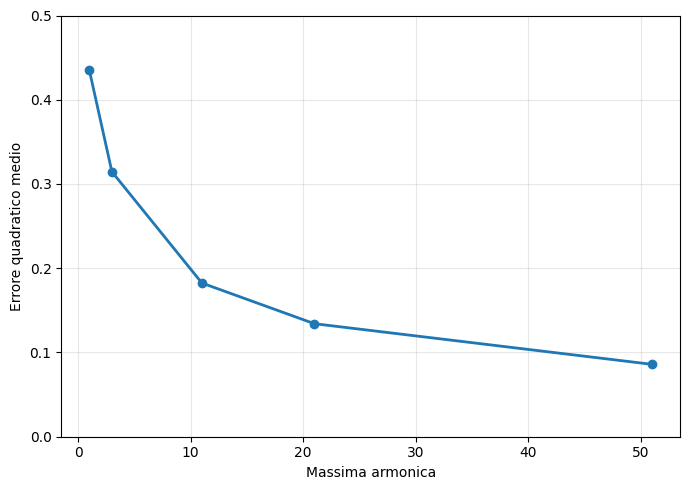

In [63]:
N_ref = 1000
y_ref = square_wave_fourier2(t, N_odd=N_ref, **params_sim)

def rms_error(y, y_ref):
    return np.sqrt(np.mean((y - y_ref)**2))   # MSE  


N_list=(1, 3, 11, 21, 51)
rms_list = []

for N in N_list:
    yN = square_wave_fourier2(t, N_odd=N, **params_sim)
    rms = rms_error(yN, y_ref)
    rms_list.append(rms)

plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2)
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



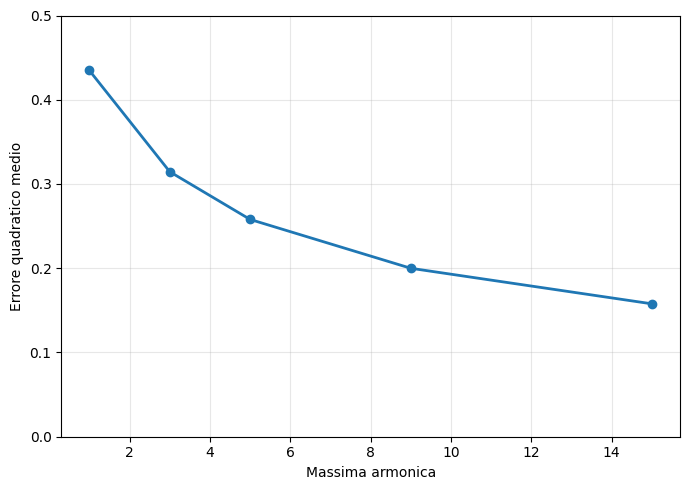

In [64]:
N_ref = 1000
y_ref = square_wave_fourier2(t, N_odd=N_ref, **params_sim)

def rms_error(y, y_ref):
    return np.sqrt(np.mean((y - y_ref)**2))   # MSE  


N_list=(1, 3, 5, 9, 15)
rms_list = []

for N in N_list:
    yN = square_wave_fourier2(t, N_odd=N, **params_sim)
    rms = rms_error(yN, y_ref)
    rms_list.append(rms)

plt.figure(figsize=(7,5))
plt.plot(N_list, rms_list, "o-", linewidth=2)
plt.xlabel("Massima armonica")
plt.ylabel("Errore quadratico medio")
plt.ylim(0,0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



ha senso solo quando massima armonico è molto minore di 1000, perchè come vera onda ne sto sando una sviluppata fino alla massima armonica 999

### Cambia campionamento

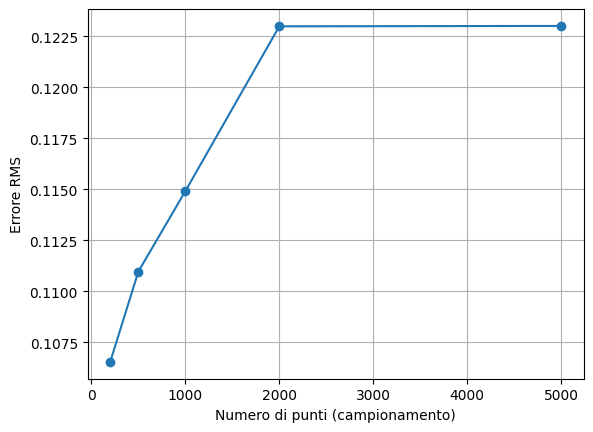

In [65]:
f0 = 1


t_ref = np.linspace(0, 3/f0, 20000)
y_ref = square_wave_fourier2(t_ref, N_odd=1000, **params_sim)


N_points_list = [200, 500, 1000, 2000, 5000]
rms_vs_sampling = []

for Np in N_points_list:
    t = np.linspace(0, 3/f0, Np)
    y = square_wave_fourier2(t, N_odd=25, **params_sim)

    # interpola il riferimento sugli stessi t
    y_ref_interp = np.interp(t, t_ref, y_ref)

    rms = np.sqrt(np.mean((y - y_ref_interp)**2))
    rms_vs_sampling.append(rms)

plt.plot(N_points_list, rms_vs_sampling, "o-")
plt.xlabel("Numero di punti (campionamento)")
plt.ylabel("Errore RMS")
plt.grid()
plt.show()


### 1.5 - Sovrapponi vero segnale

#### Quadra

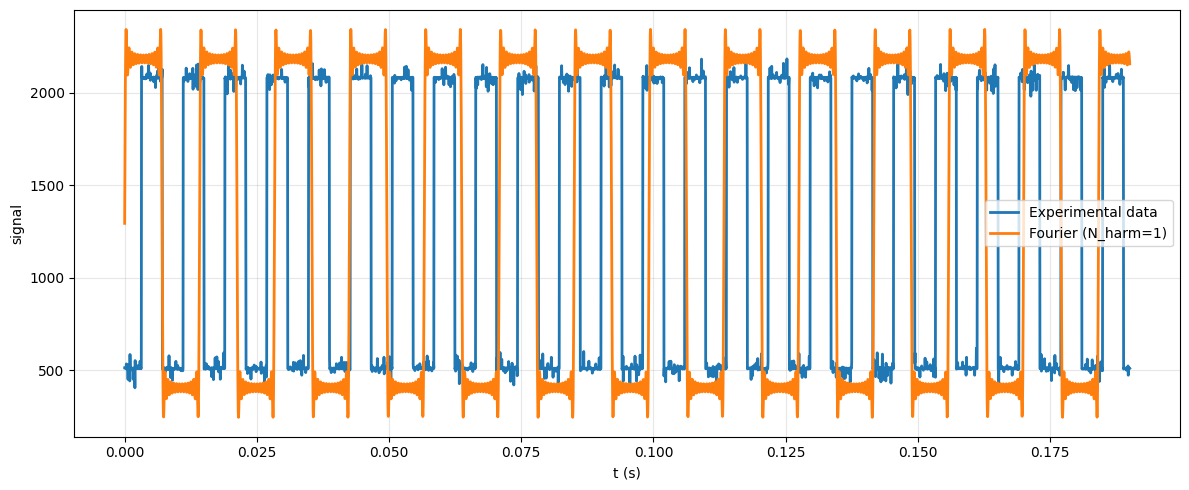

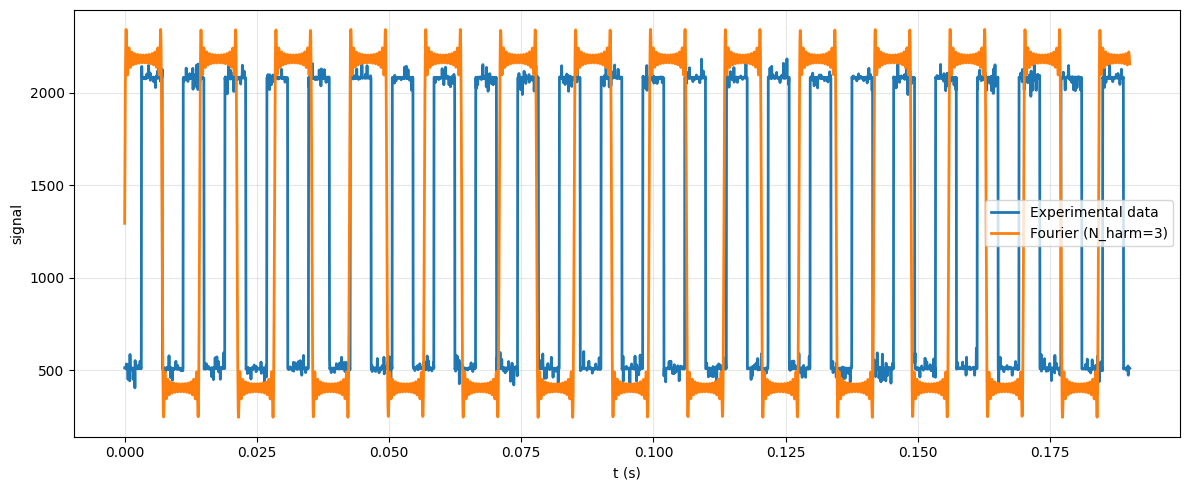

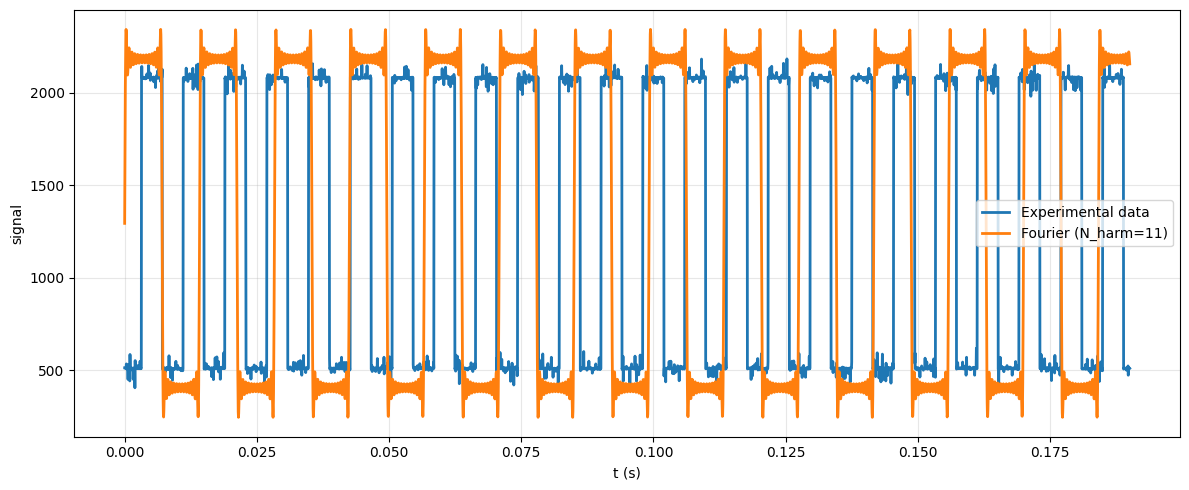

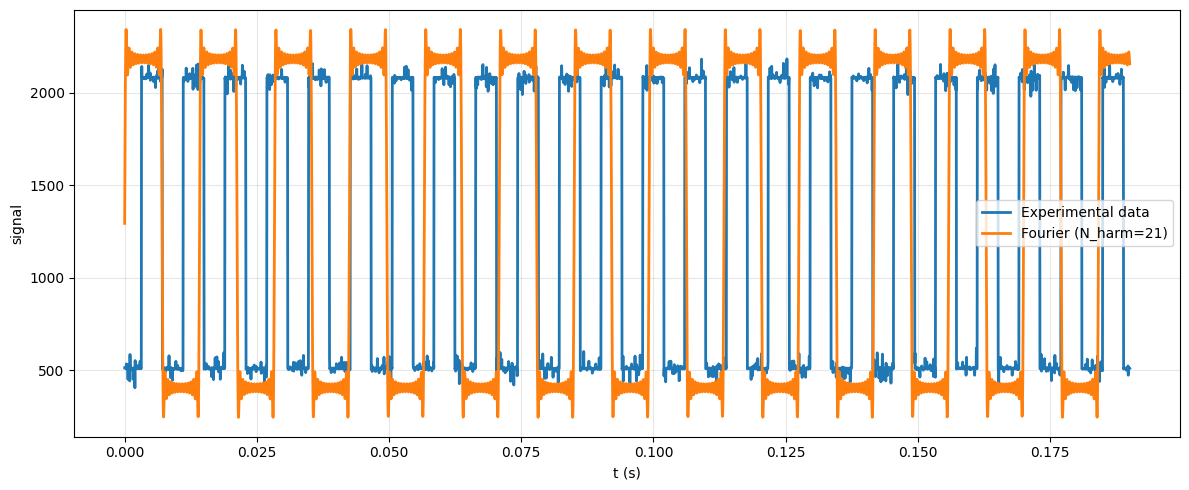

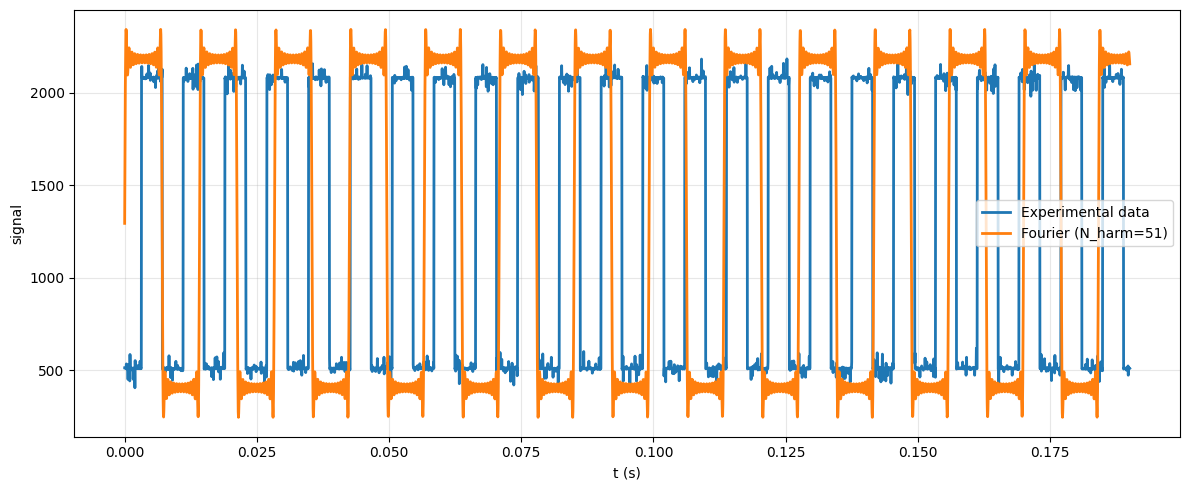

{'f0': 70.59487951807229,
 'A': 889.0,
 'offset': 1294.821533203125,
 'phi0': 2.3900025814132873}

In [66]:
dir1 = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/Per_prossimo_esperimento/'
file1 = 'data_quadra.txt'

t1, y1, params1 = upload(dir1, file1)
multiple_fourier_series(t1, y1, params1)

# PROBLEM WITH PARAMS???? WHY NOT FOUND ANYMORE???

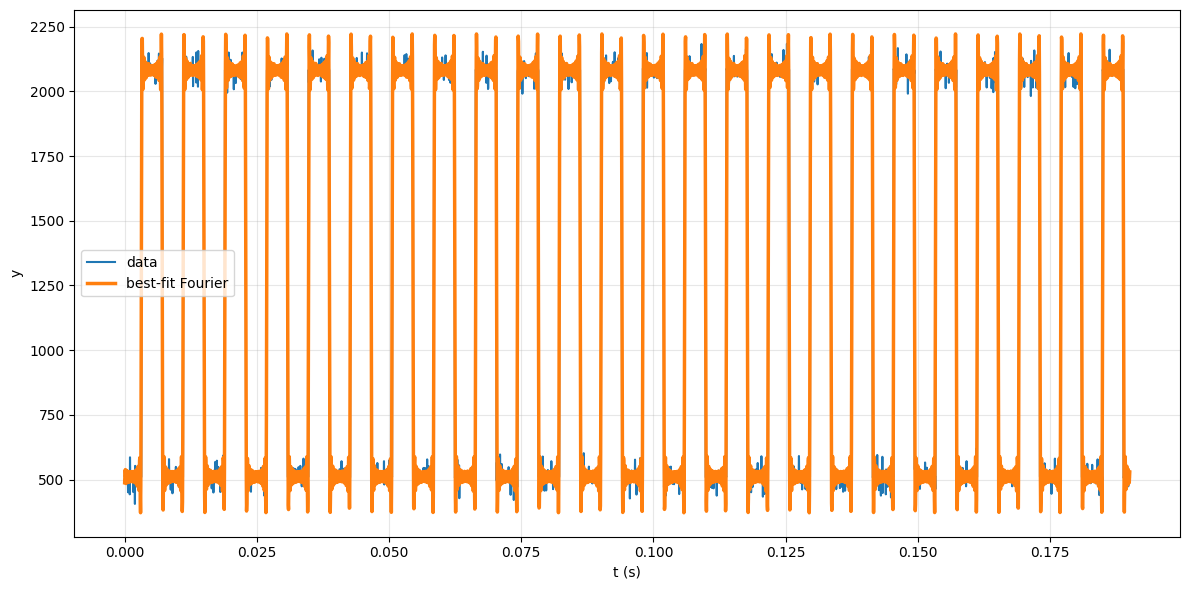

In [67]:
params1 = bestfit_fourier_params2(t1,y1)

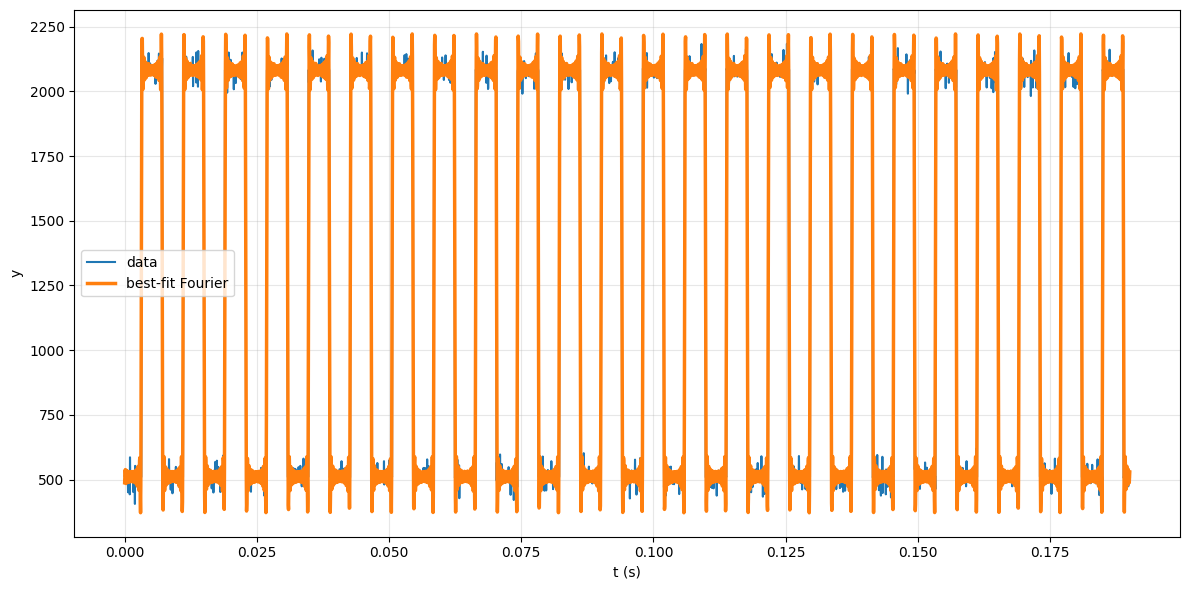

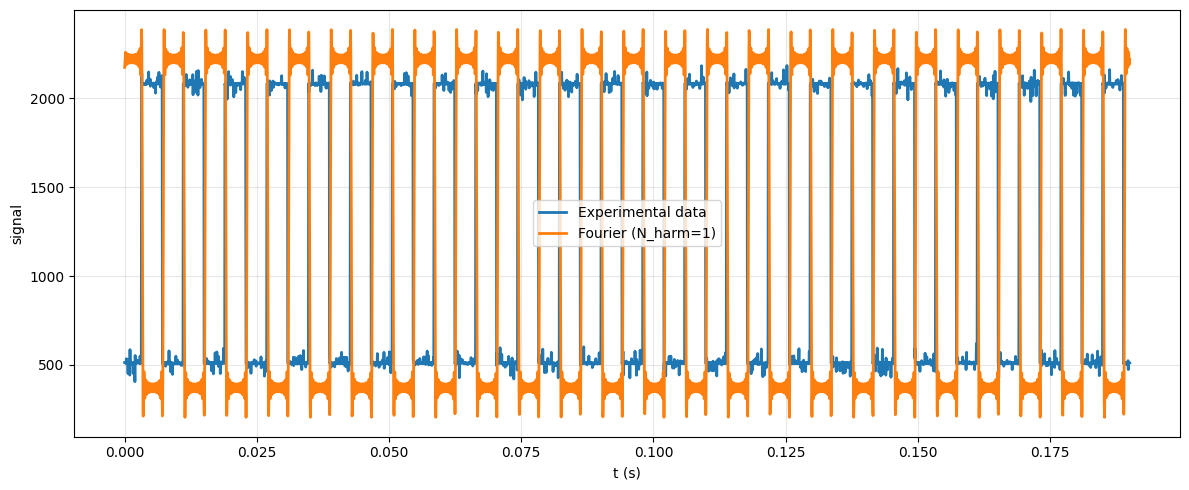

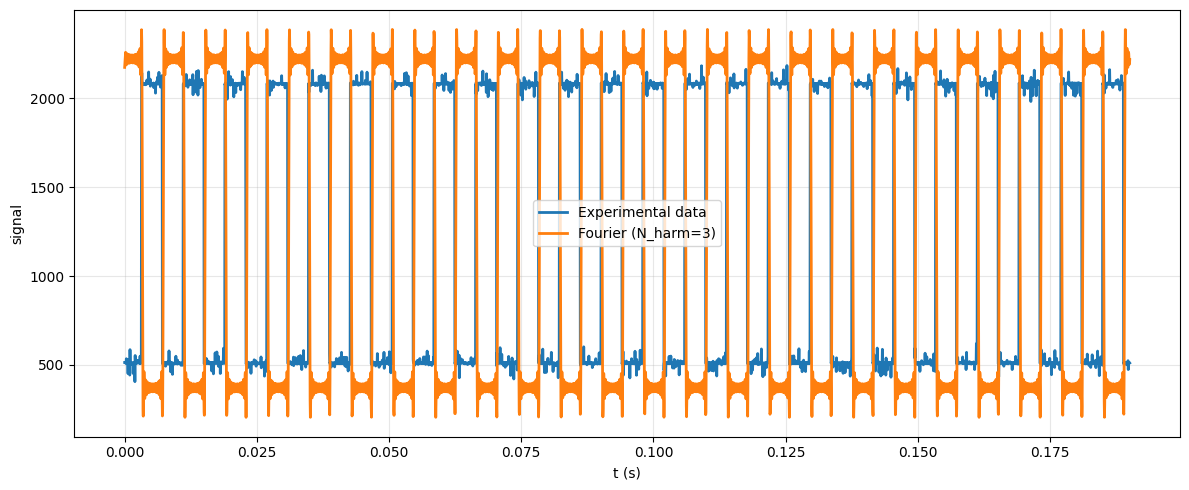

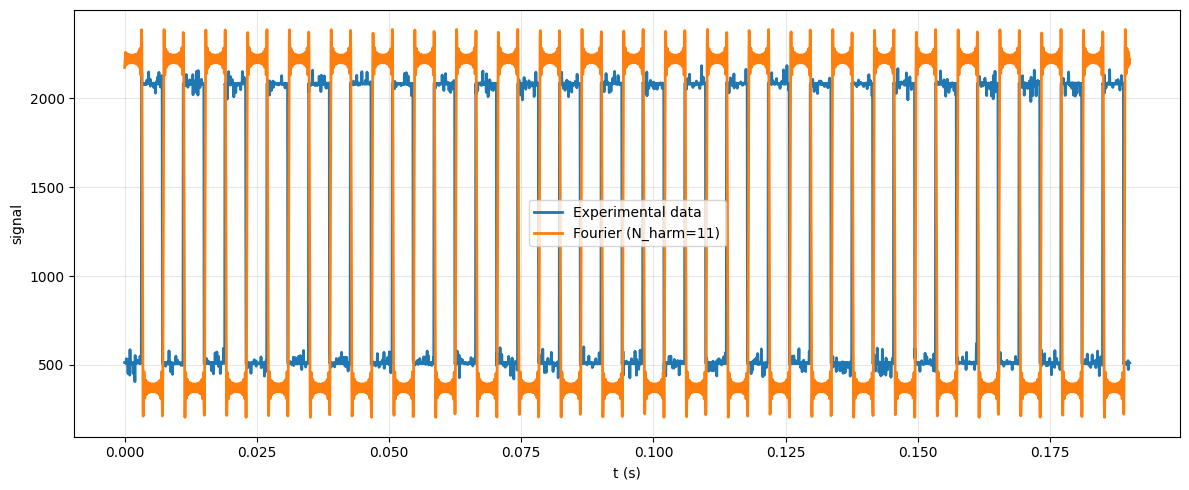

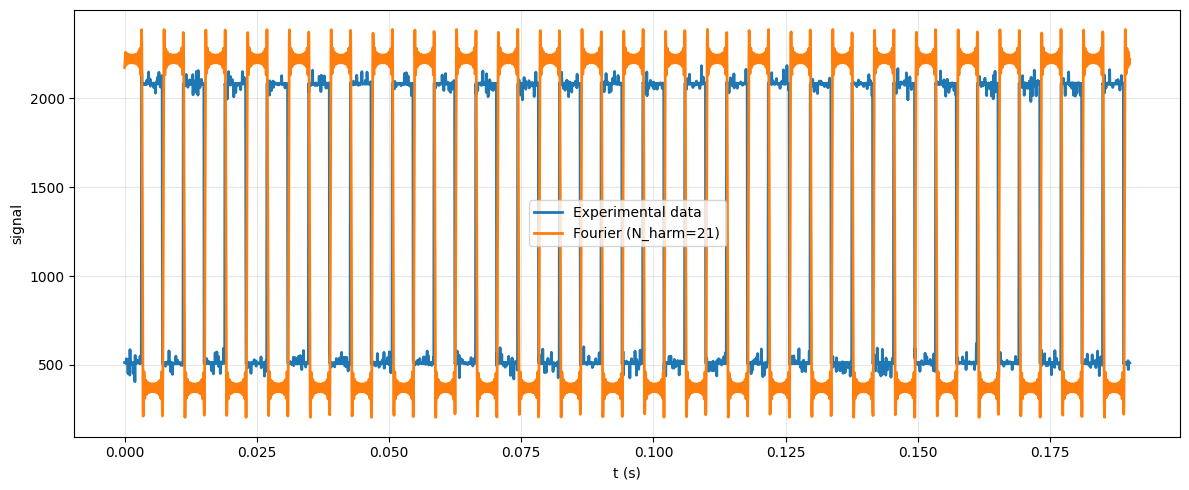

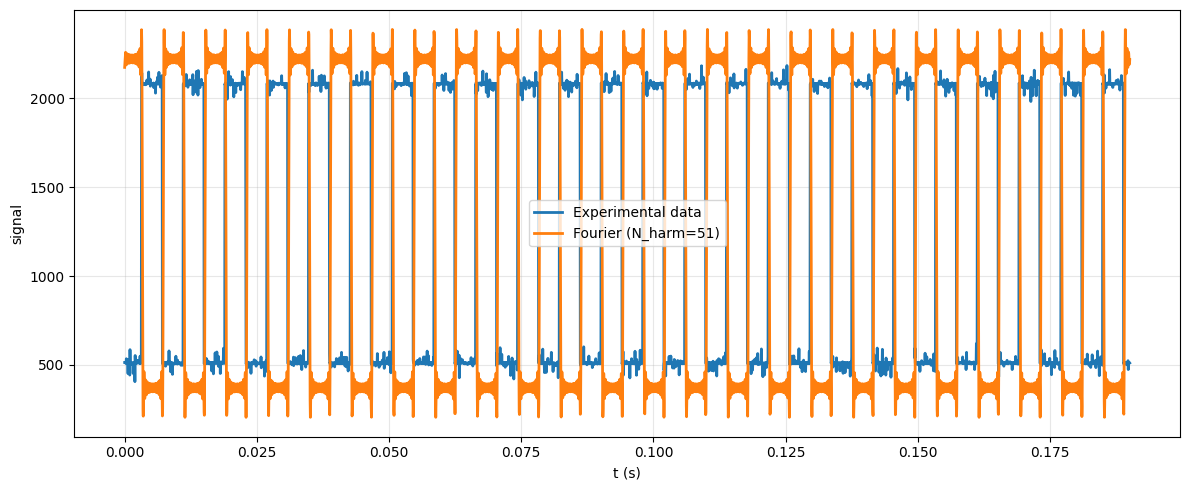

{'f0': 126.53180609676548,
 'A': 925.0608240482802,
 'offset': 1296.4522182087974,
 'phi0': 89328.52320387364,
 't0': -112.35970200348694,
 'N': 25,
 'beta': array([ 1.29645222e+03, -1.55222921e+02, -9.88049594e+02,  9.65044766e-02,
         2.20403038e-01, -1.50179724e+02, -2.98022107e+02, -2.23060231e-01,
         1.50682093e-01, -1.40984202e+02, -1.41521696e+02, -2.37972689e-01,
         1.92776807e-02, -1.27195189e+02, -6.54783354e+01,  2.45304651e-01,
         2.59570232e-01, -1.08902940e+02, -1.84107358e+01, -4.04463541e-01,
         3.48833037e-01, -8.95653281e+01,  1.38612345e+01,  1.21842751e-01,
        -6.90425040e-02, -6.90552705e+01,  3.34751170e+01,  1.03721802e+00,
         1.04403003e-01, -4.75295253e+01,  4.64464436e+01,  2.33915508e-01,
         1.00322318e-01, -2.75454068e+01,  5.16893501e+01,  2.32521898e-01,
         5.49888923e-01, -9.26528106e+00,  5.16846903e+01,  8.92504489e-01,
        -3.36530248e-02,  6.14437419e+00,  4.66059122e+01, -7.98336356e-02,
       

In [68]:
params1, _, _ = bestfit_fourier_params2(t1,y1)
params1['phi0'] = params1['phi0']  # NON FUNZIONA
multiple_fourier_series(t1, y1, params1)

# problema con offset, perrò quando lo faccio plottare da bestfit_fourier_params viene bene, confronta le due funzioni che plottano e vedi la differeza
# sennò, se aggiungo un phi si aggiusta
# però ho anche problemi di ampiezza???

# primo grafico è dato da bestfit_fourier_params, fli altri da multiple_fourier series

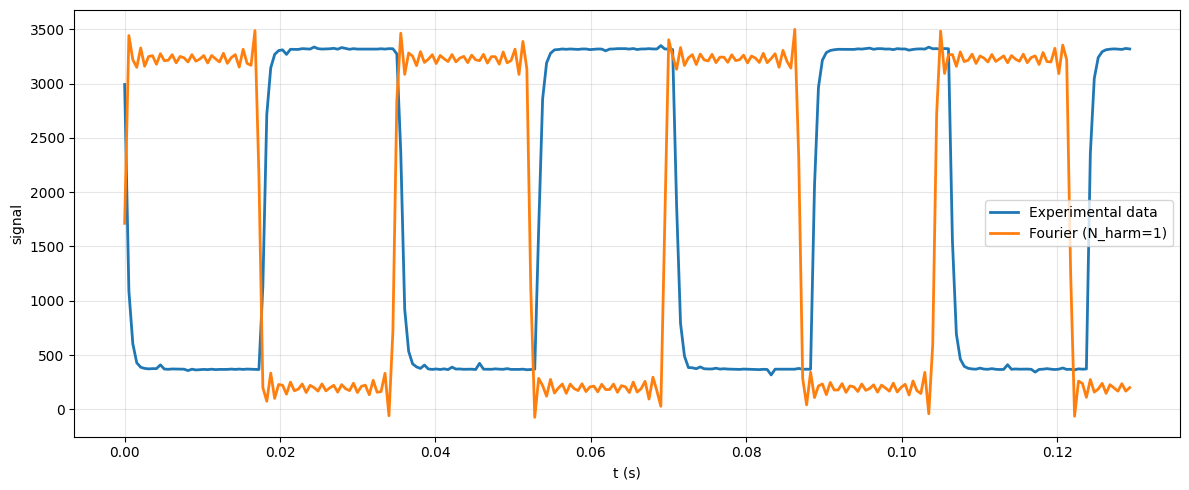

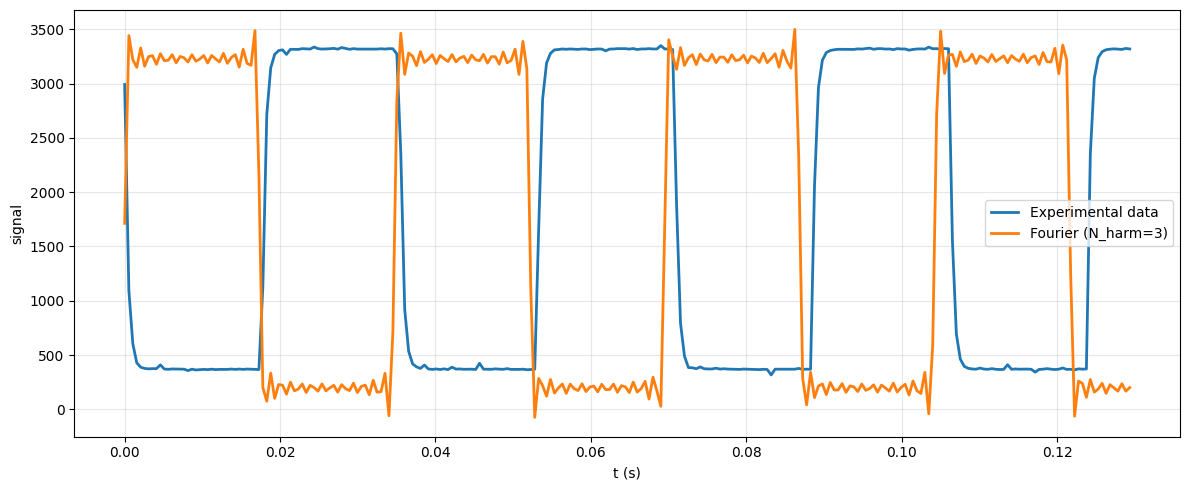

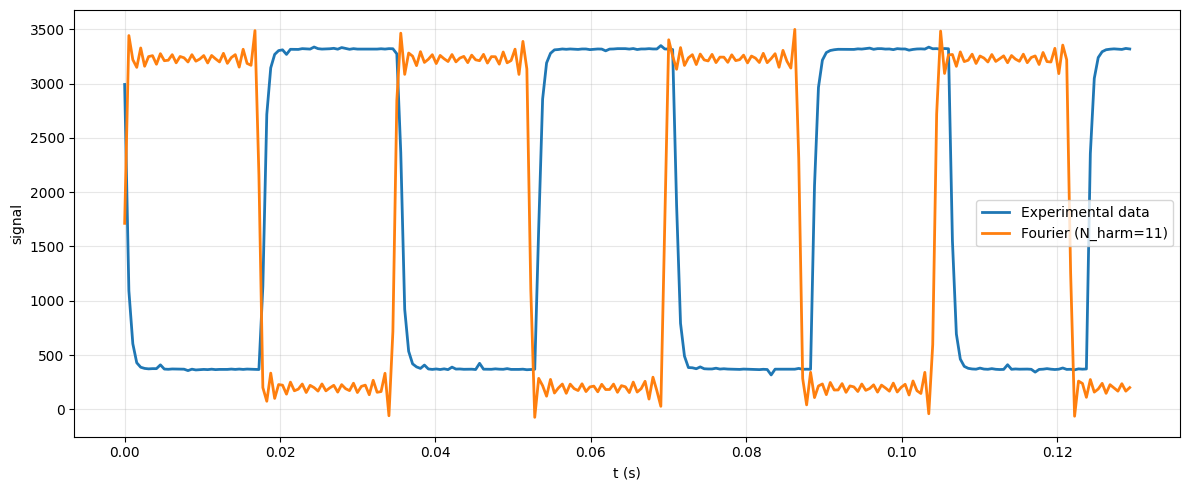

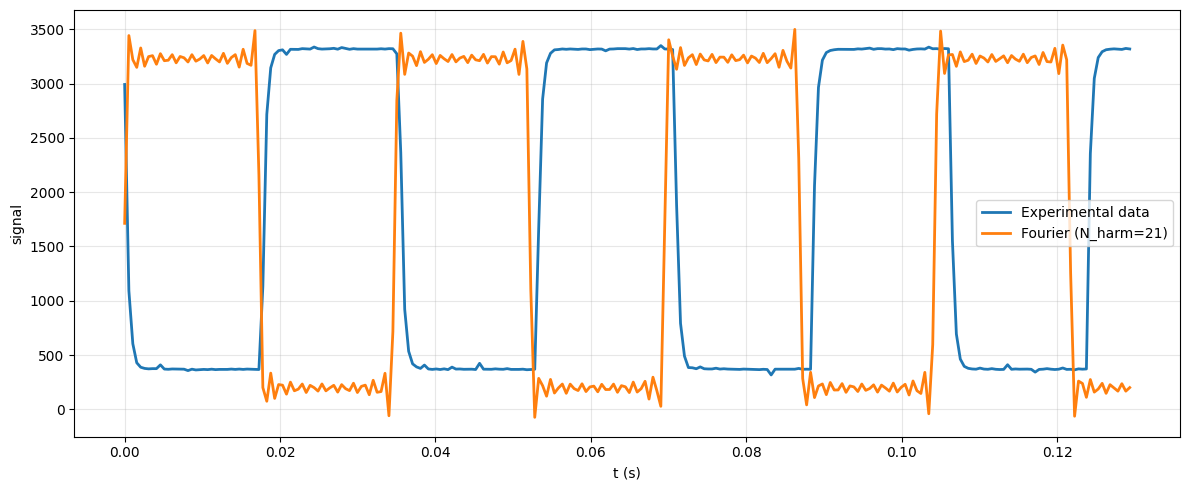

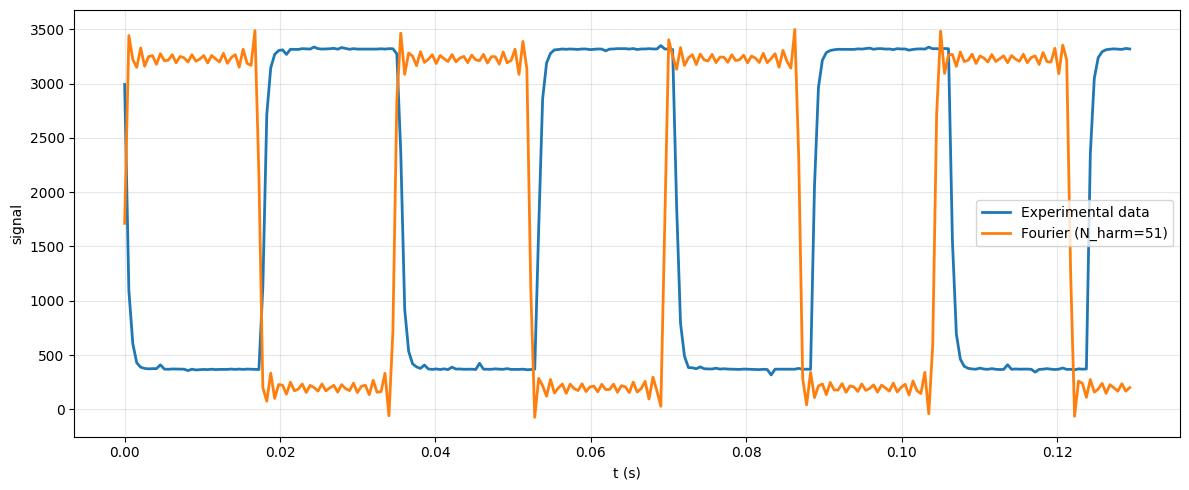

{'f0': 28.77532228360958,
 'A': 1516.5,
 'offset': 1713.25,
 'phi0': 0.5112635963777318}

In [69]:
dir2 = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/'
file2 = 'integratore_1.txt'

t2, y2, params2 = upload(dir2, file2)
multiple_fourier_series(t2, y2, params2)

# PROBLEM WITH OFFSET (but better than before)

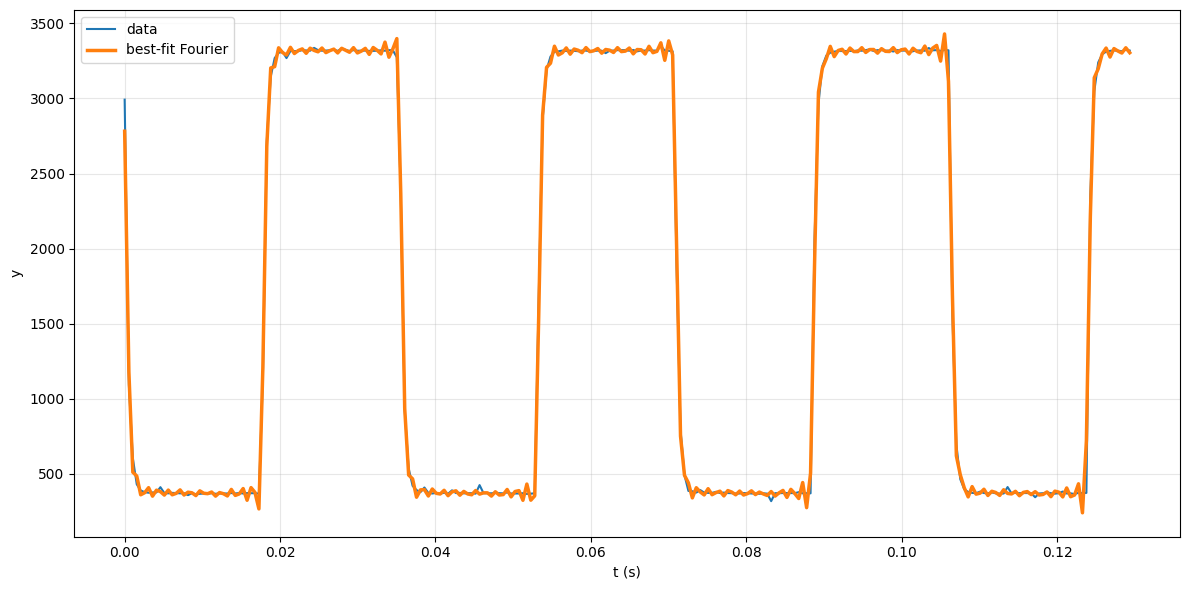

({'f0': 28.259064357714447, 'A': 1595.2055808616535, 'offset': 1846.4872060542261, 'phi0': 53668.969236773955, 't0': -302.2634308254316, 'N': 25, 'beta': array([ 1.84648721e+03, -1.75075247e+03,  6.62782180e+02, -2.88806667e+00,
        1.31042756e+00,  2.80688152e+02, -5.42185927e+02, -8.29805506e-01,
       -2.87891568e+00,  9.11224827e+01,  3.40945499e+02,  1.66236412e+00,
        1.32579305e+00, -2.04031832e+02, -1.27472167e+02, -1.83099253e+00,
       -1.57644877e+00,  1.71606740e+02, -3.50463557e+01,  2.82310011e+00,
       -2.03579969e+00, -7.52154432e+01,  1.09427179e+02, -1.58411162e+00,
        1.19578344e+00, -1.98140733e+01, -1.03064176e+02, -1.07808067e+00,
       -1.95277802e+00,  6.96558930e+01,  4.63908220e+01,  1.83470273e+00,
        1.20595417e+00, -6.67696243e+01,  1.62354341e+01, -1.57638325e+00,
        8.98154371e-01,  2.79111065e+01, -5.04084845e+01, -2.70490168e-02,
       -8.55097670e-01,  1.50340647e+01,  4.68830293e+01, -8.84248140e-02,
        1.26121660e+0

In [70]:
params2 = bestfit_fourier_params2(t2,y2)
# params2['phi0'] = params2['phi0'] - np.pi/2
# multiple_fourier_series(t2, y2, params2)
print(params2)


#### Triangolare

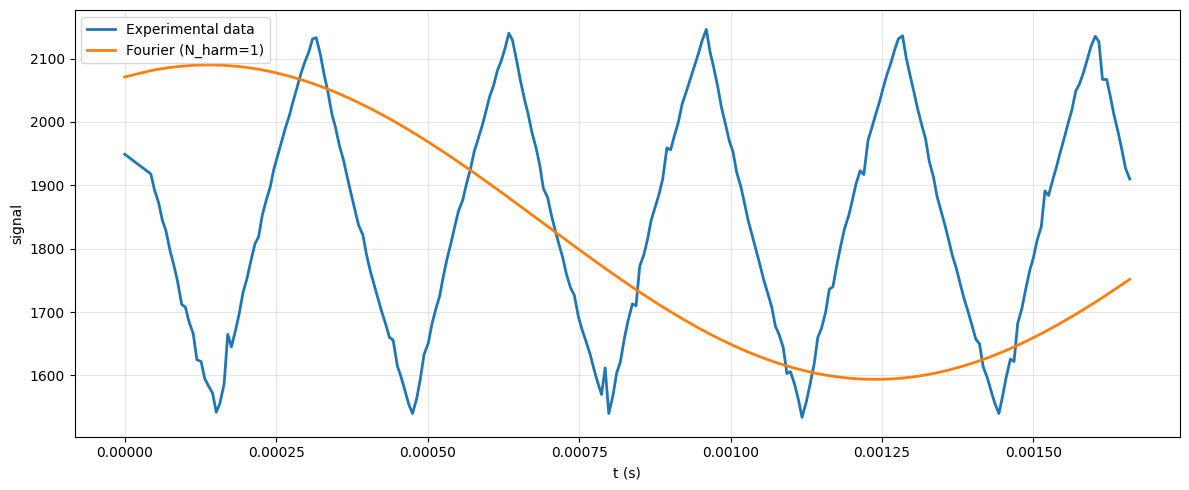

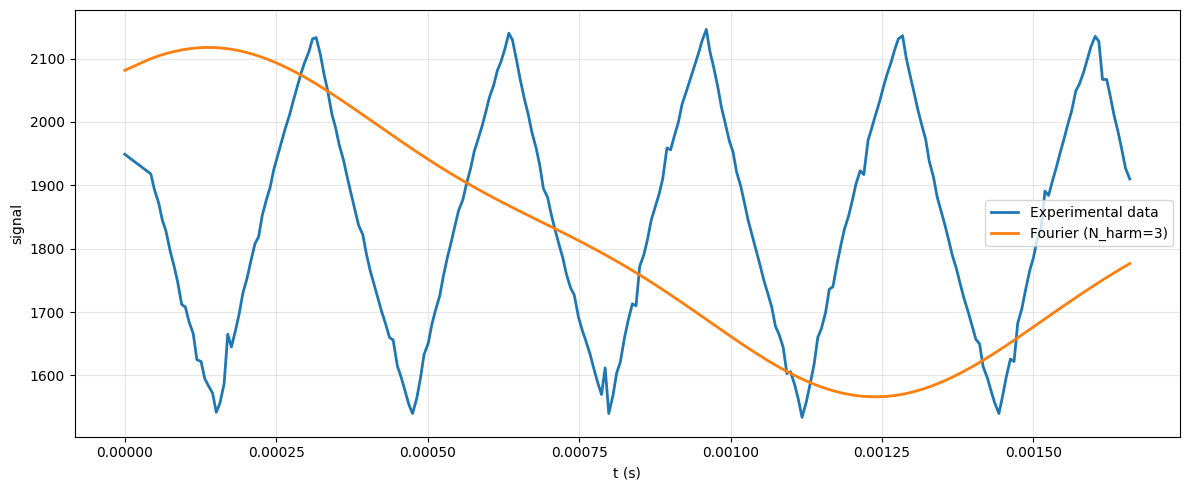

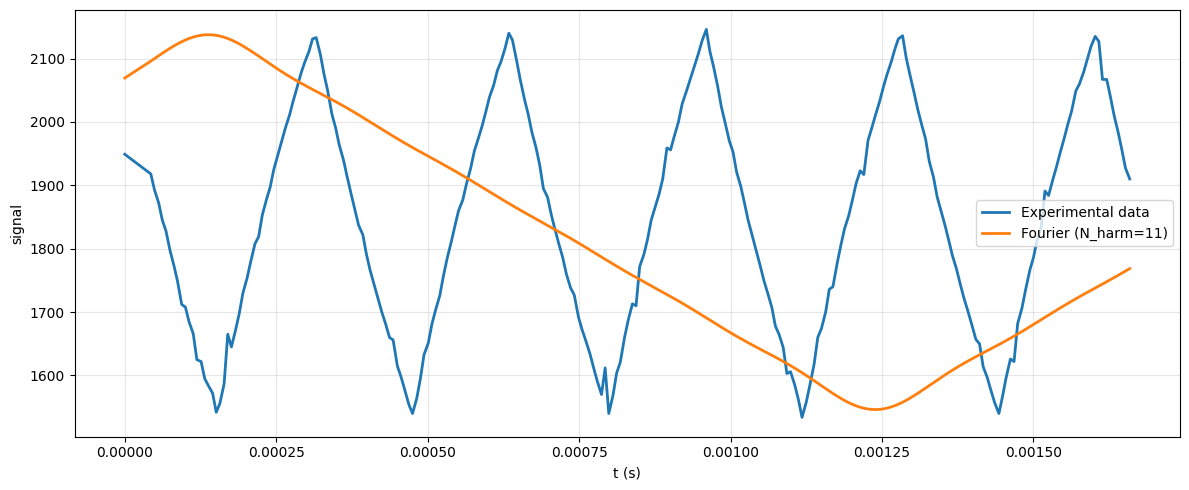

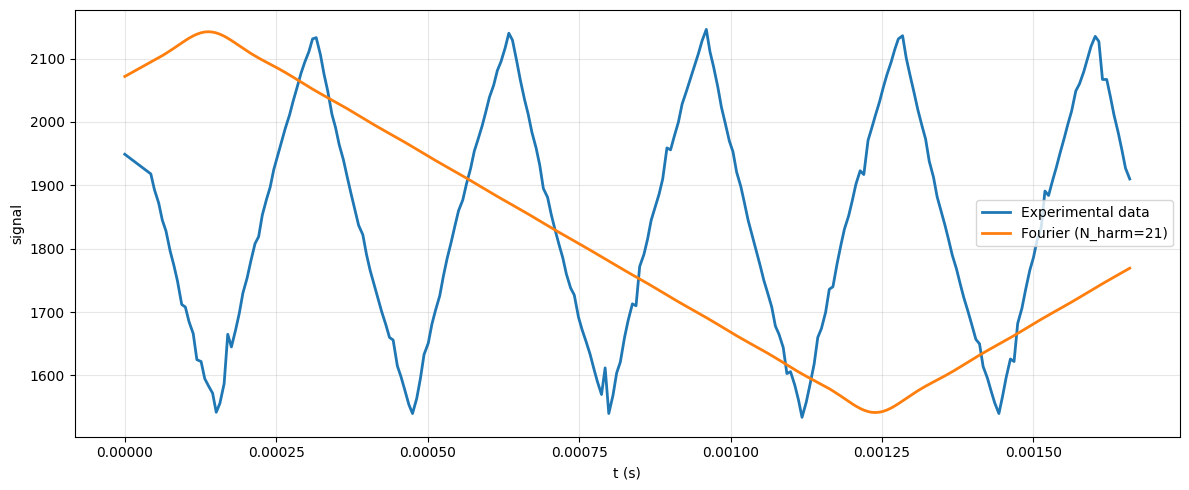

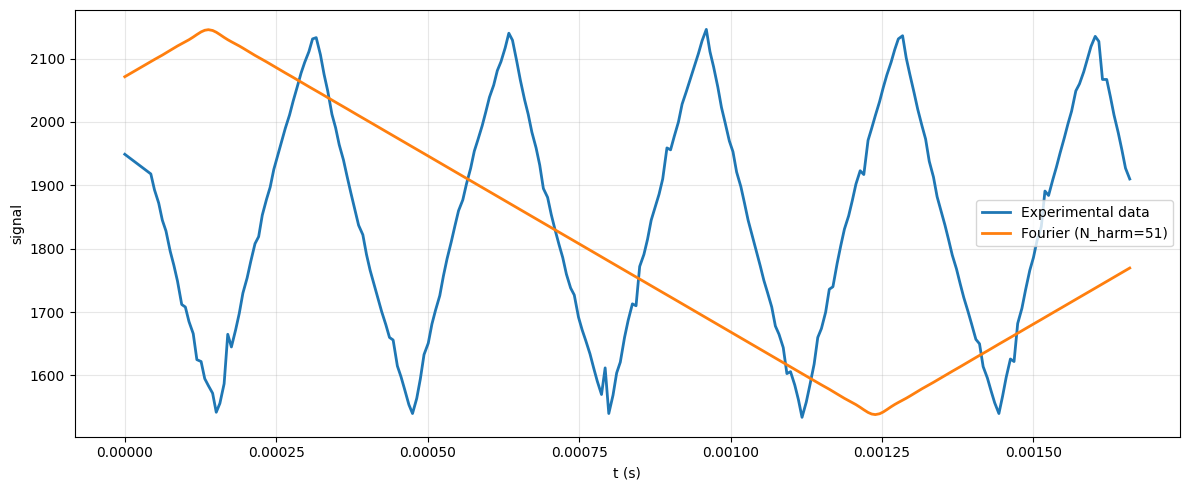

{'f0': 454.2151162790698,
 'A': 306.0,
 'offset': 1841.93359375,
 'phi0': 1.176871762640453}

In [71]:
# Import

file3 = 'integratore_9.txt'

t3, y3, params3 = upload(dir2, file3)
multiple_fourier_series_tr(t3, y3, params3)

# Problems with frequency??? is mistake in function that finds params??? pick the one from your notes

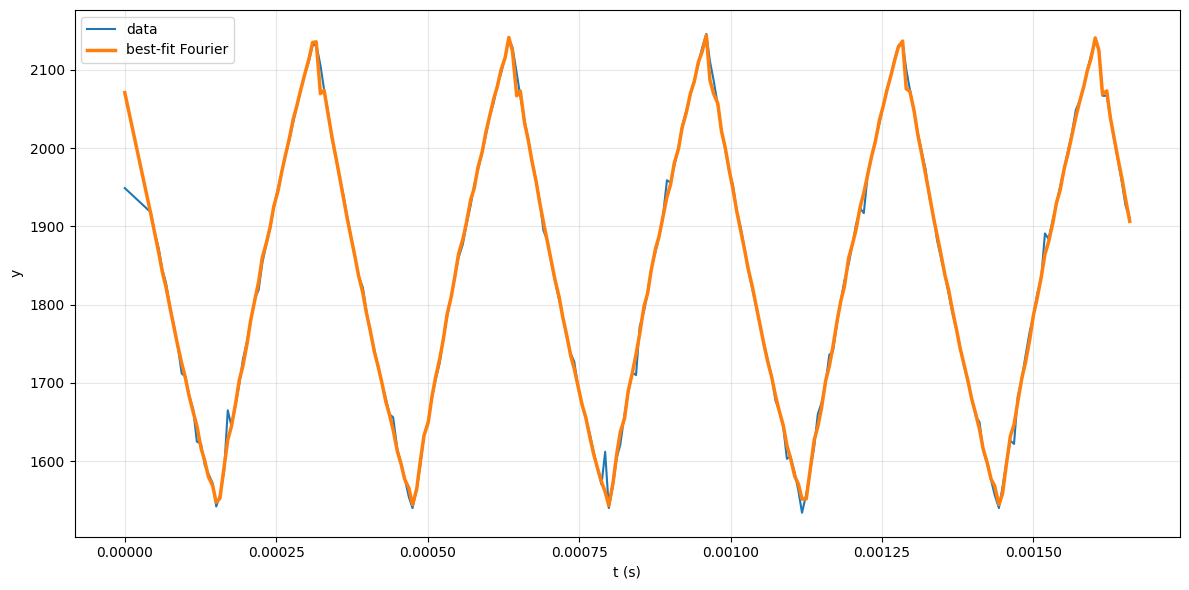

TypeError: __main__.square_wave_fourier2() argument after ** must be a mapping, not tuple

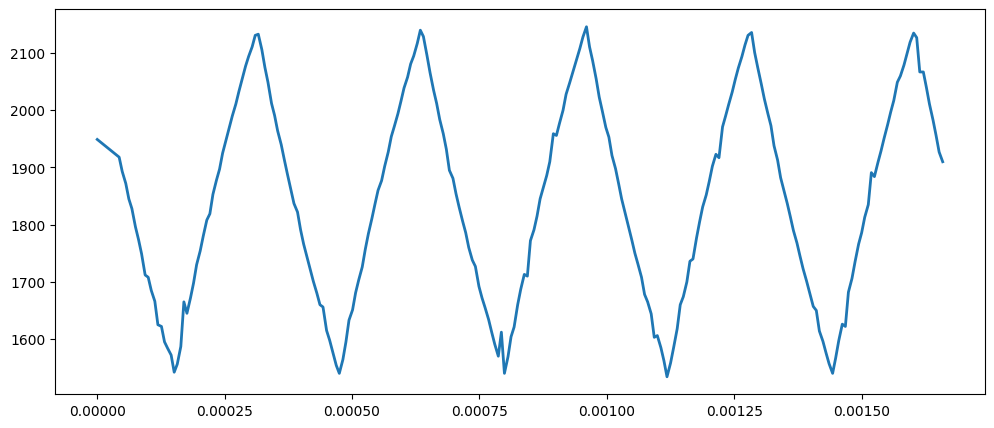

In [72]:
params4 = bestfit_fourier_params2(t3,y3)
# params2['phi0'] = params2['phi0'] - np.pi/2
multiple_fourier_series(t3, y3, params4)


### 2- simulazione pinna di squalo

/tmp/ipykernel_11425/2063294251.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


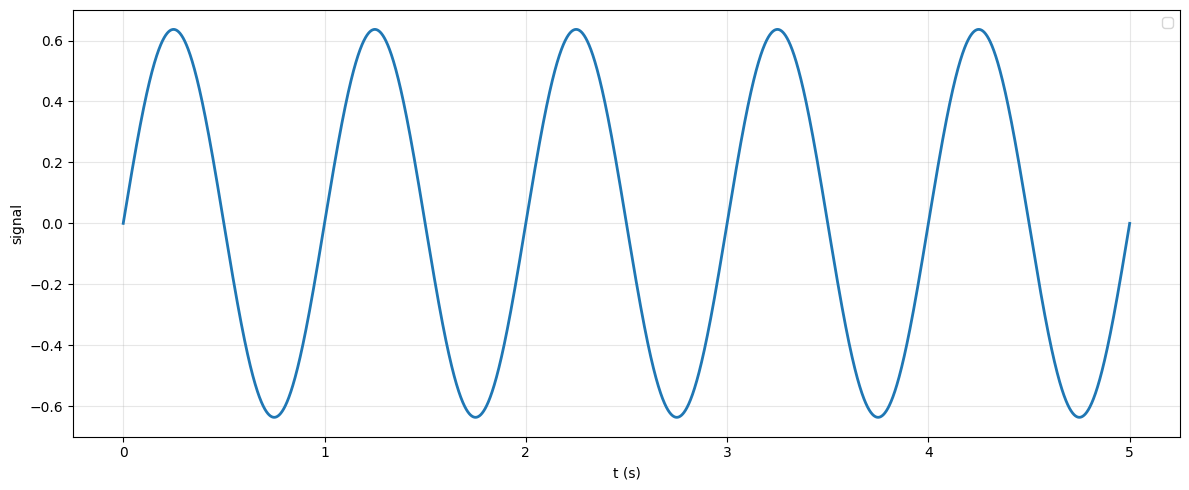

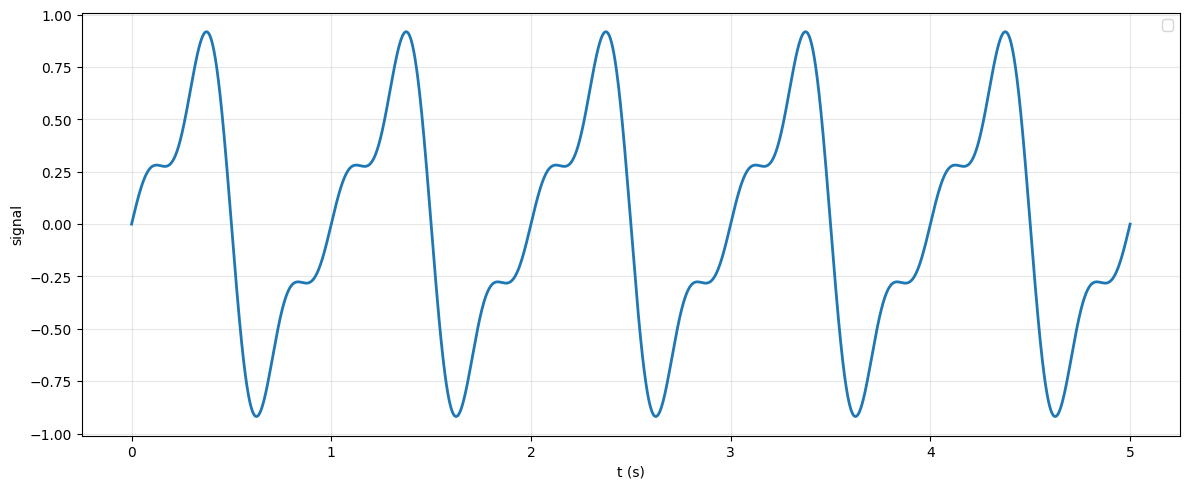

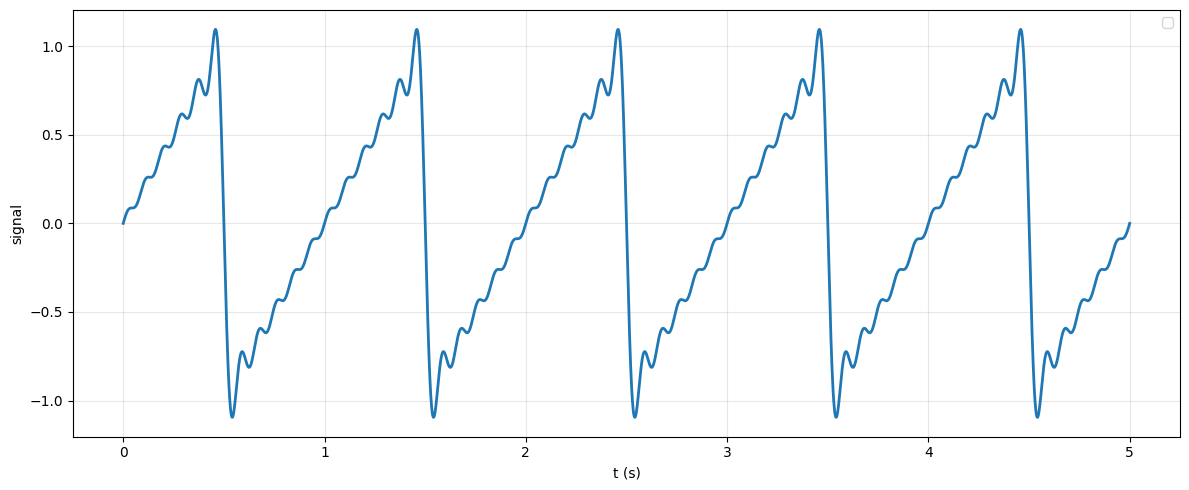

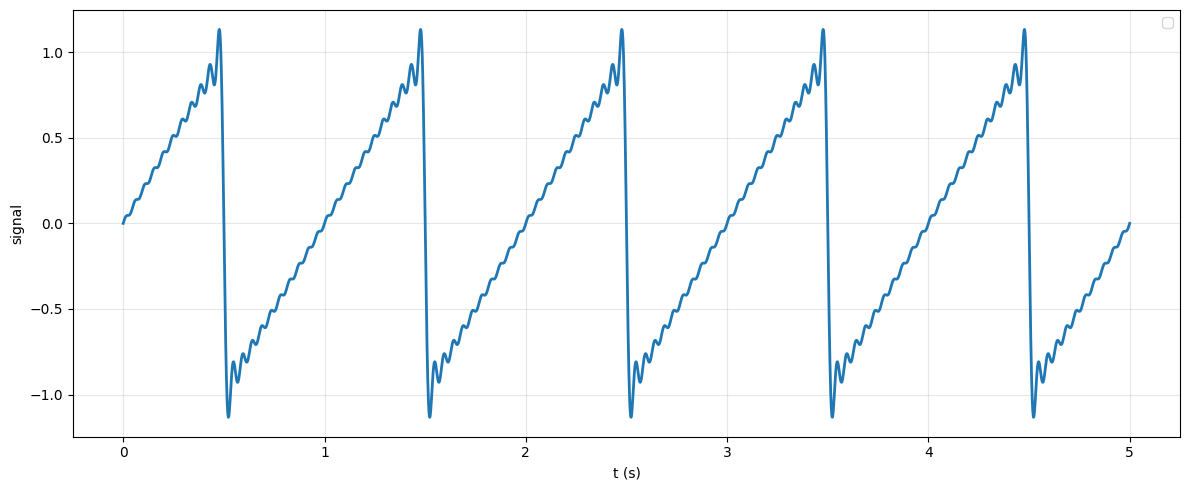

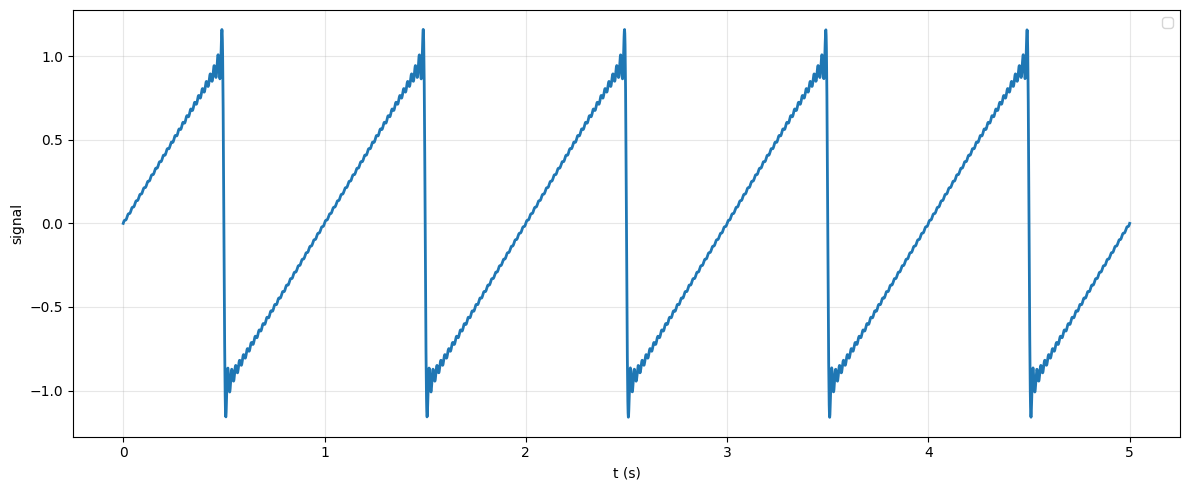

In [136]:
# Triangle wave

for N_harm in N_list:
        y = shark_fin_wave_fourier(t, N_harm=N_harm, **params_sim)

        plt.figure(figsize=(12, 5))
        plt.plot(t, y, linewidth=2.0)

        plt.xlabel("t (s)")
        plt.ylabel("signal")
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()

### 3 - Sovrapponi vero segnale

### 4 - guadagno vs frequenza

In [73]:
Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/'
NomeFile = 'guadagno.txt'
Filename=(Directory+NomeFile)
f, Vout=np.loadtxt(Filename,unpack=True)

In [74]:
Vin = 2.9
G = Vout / Vin

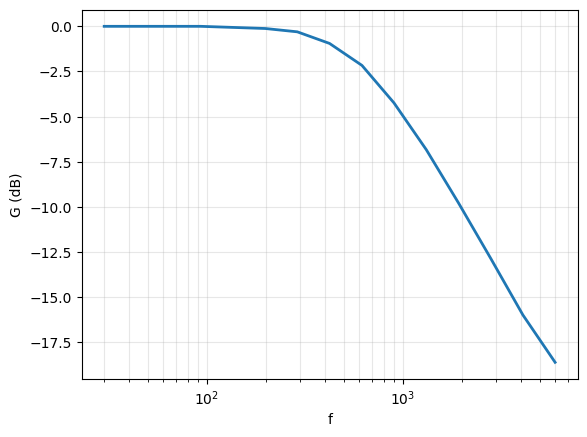

In [75]:
mag_db = 20 * np.log10(np.abs(G))

plt.plot(f, mag_db, linewidth=2)
plt.xscale('log')
plt.ylabel('G (dB)')
plt.xlabel('f')
plt.grid(True, which='both', alpha=0.3)

plt.show()

### 5 - con forma triangolare

#### Formula integratore

In [140]:
def ideal_integrator_from_fourier(t, A, f0, N_harm, K, wave="square"):
    """
    Uscita di un integratore ideale applicato a un'onda periodica
    costruita via Fourier.

    wave = "square" o "triangle"
    """
    w0 = 2 * np.pi * f0
    y = np.zeros_like(t)

    if wave == "square":
        for n in range(1, N_harm + 1, 2):
            y += (4*A/np.pi) * (1/n) * (K/(n*w0)) * (-np.cos(n*w0*t))

    elif wave == "triangle":
        for n in range(1, N_harm + 1, 2):
            sign = (-1)**((n-1)//2)
            y += (8*A/np.pi**2) * (sign/n**2) * (K/(n*w0)) * (-np.cos(n*w0*t))

    else:
        raise ValueError("wave deve essere 'square' o 'triangle'")

    # rimuovo la costante di integrazione
    return y - np.mean(y)


# nota che K = tau di taglio


#### Bode plot

In [42]:
Directory= '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/'
NomeFile = 'guadagno_tri.txt'
Filename=(Directory+NomeFile)
f, Vout=pl.loadtxt(Filename,unpack=True)

NameError: name 'pl' is not defined

In [83]:
Vin = 2.9
G = Vout / Vin

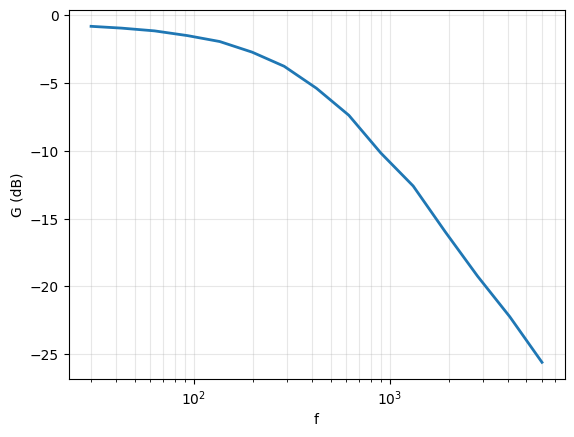

In [84]:
mag_db = 20 * np.log10(np.abs(G))

plt.plot(f, mag_db, linewidth=2)
plt.xscale('log')
plt.ylabel('G (dB)')
plt.xlabel('f')
plt.grid(True, which='both', alpha=0.3)

plt.show()

### CONTROLLA CARATTERISTICHE DI ONDA

=== BEST-FIT Fourier ===
Armoniche N           = 25
f (Hz)                = 126.532
omega (rad/s)         = 795.023
t0 (s)                = 1.21179
offset (y)            = 1296.45
ampiezza ~ (pp/2)     = 925.061
RMSE                  = 98.6357


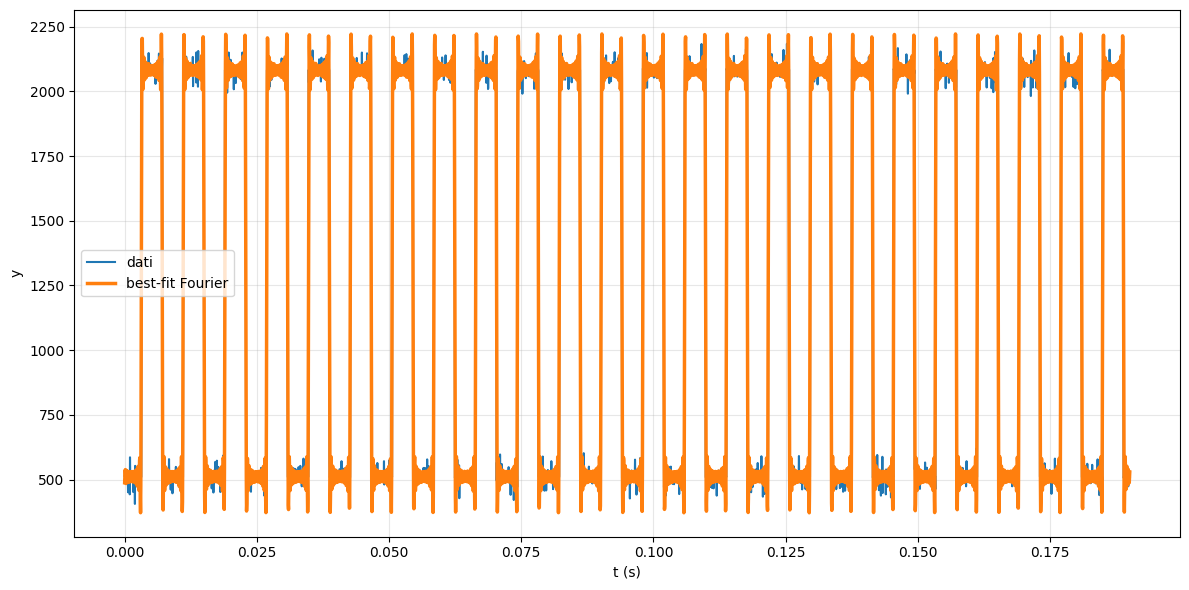

In [142]:
import numpy as np
import matplotlib.pyplot as plt

# Se non hai SciPy: pip install scipy
from scipy.optimize import least_squares

# ----------------------------
# 1) Lettura dati
# ----------------------------
# path = "/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/dati_natale/integratore_1.txt"
path = '/home/gea/Desktop/notebooks/Notebooks/Year_2/Lab_2/Esercizio fft/Per_prossimo_esperimento/data_quadra.txt'

data = np.loadtxt(path)
t_raw = data[:, 0].astype(float)
y = data[:, 1].astype(float)

# Heuristica: se t è "grande" (es. microsecondi o contatori), converti in secondi.
# Puoi forzare tu questa parte se sai l'unità.
t = t_raw.copy()
if t.max() > 1000:          # tipico: microsecondi o "tick"
    t = t * 1e-6            # microsecondi -> secondi (se invece sono ms: usa 1e-3)

# centra il tempo per stabilità numerica
t = t - t.min()

# ----------------------------
# 2) Stima iniziale della frequenza (FFT)
# ----------------------------
# campionamento (assume circa uniforme)
dt = np.median(np.diff(t))
fs = 1.0 / dt

y_detr = y - np.mean(y)
Y = np.fft.rfft(y_detr)
freqs = np.fft.rfftfreq(len(y_detr), d=dt)

# ignora DC e prendi picco massimo
k0 = 1
k_peak = k0 + np.argmax(np.abs(Y[k0:]))
f0 = freqs[k_peak]
if f0 <= 0:
    f0 = 1.0  # fallback

# ----------------------------
# 3) Modello: serie di Fourier con N armoniche
#    y(t) ≈ c0 + Σ [a_n cos(n ω (t - t0)) + b_n sin(n ω (t - t0))]
#    Per dati (ω,t0) -> (c0, a_n, b_n) si stimano con least squares lineare.
# ----------------------------
def design_matrix(t, omega, t0, N):
    # colonne: [1, cos(1..N), sin(1..N)]
    tau = t - t0
    cols = [np.ones_like(t)]
    for n in range(1, N + 1):
        cols.append(np.cos(n * omega * tau))
        cols.append(np.sin(n * omega * tau))
    return np.column_stack(cols)

def fit_linear_coeffs(t, y, omega, t0, N):
    X = design_matrix(t, omega, t0, N)
    # least squares lineare
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    yhat = X @ beta
    return beta, yhat

def residuals_nonlinear(p, t, y, N):
    # p = [log_f, t0] per vincolare f>0 in modo robusto
    log_f, t0 = p
    f = np.exp(log_f)
    omega = 2 * np.pi * f
    _, yhat = fit_linear_coeffs(t, y, omega, t0, N)
    return (yhat - y)

# ----------------------------
# 4) Esegui best-fit (nonlineare solo su f e t0)
# ----------------------------
N = 25  # numero armoniche (aumenta: 35/51 se serve più "spigolo")

p0 = np.array([np.log(f0), 0.0])  # t0 iniziale 0
res = least_squares(
    residuals_nonlinear,
    p0,
    args=(t, y, N),
    loss="soft_l1",       # robusto a outlier
    f_scale=np.std(y) if np.std(y) > 0 else 1.0,
    max_nfev=400
)

log_f_opt, t0_opt = res.x
f_opt = float(np.exp(log_f_opt))
omega_opt = 2 * np.pi * f_opt

beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, t0_opt, N)

# ----------------------------
# 5) Estrai parametri “leggibili”
# ----------------------------
offset_opt = beta_opt[0]

# Ampiezza "globale" del fit (picco-picco /2) sul segmento osservato:
A_pp = float(yhat_opt.max() - yhat_opt.min())
A_opt = 0.5 * A_pp

print("=== BEST-FIT Fourier ===")
print(f"Armoniche N           = {N}")
print(f"f (Hz)                = {f_opt:.6g}")
print(f"omega (rad/s)         = {omega_opt:.6g}")
print(f"t0 (s)                = {t0_opt:.6g}")
print(f"offset (y)            = {offset_opt:.6g}")
print(f"ampiezza ~ (pp/2)     = {A_opt:.6g}")
print(f"RMSE                  = {np.sqrt(np.mean((yhat_opt - y)**2)):.6g}")

# ----------------------------
# 6) Plot
# ----------------------------
plt.figure(figsize=(12, 6))
plt.plot(t, y, linewidth=1.5, label="dati")
plt.plot(t, yhat_opt, linewidth=2.5, label="best-fit Fourier")
plt.grid(True, alpha=0.3)
plt.xlabel("t (s)")
plt.ylabel("y")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# 7) (Opzionale) salva coefficenti
# ----------------------------
# beta = [c0, a1, b1, a2, b2, ..., aN, bN]
#np.savetxt("fourier_fit_coeffs.txt", beta_opt)
# print("Salvati coefficienti in: fourier_fit_coeffs.txt")


In [153]:
def bestfit_fourier_params(
    t_raw,
    y,
    N=25,
    time_unit="auto",          # "auto", "s", "us", "ms", or float scale factor (e.g. 1e-6)
    center_time=True,
    robust=True,
    max_nfev=400,
    return_fit=False,    # put True to receive the fitted function too
    plot=False,
):
    """
    Fit a Fourier series to data, optimizing only frequency f and time-shift t0,
    while solving Fourier coefficients linearly for each (f, t0).
    
    Returns a params dict compatible with your waveform generators:
        params = {"f0": f_opt, "A": A_opt, "offset": offset_opt, "phi0": 0.0, ...}

    Notes:
    - This fit is a *general Fourier series* (cos+sin), not specifically a square.
      So phi0 is not uniquely defined; we return phi0=0 and provide t0 + beta.
    - If you want a square/triangle/sawtooth with your param-style, use f0 + t0.
    """

    # ----------------------------
    # 1) time conversion to seconds
    # ----------------------------
    t_raw = np.asarray(t_raw, dtype=float)
    y = np.asarray(y, dtype=float)

    t = t_raw.copy()

    if isinstance(time_unit, (int, float)):          # user gives scale factor to seconds
        t = t * float(time_unit)
    else:
        tu = str(time_unit).lower()
        if tu == "s":
            pass
        elif tu == "us":
            t = t * 1e-6
        elif tu == "ms":
            t = t * 1e-3
        elif tu == "auto":
            # heuristic: if big numbers -> assume microseconds
            if np.nanmax(t) > 1000:
                t = t * 1e-6
        else:
            raise ValueError("time_unit must be 'auto', 's', 'us', 'ms', or a numeric scale factor")

    if center_time:
        t = t - np.nanmin(t)

    # ----------------------------
    # 2) initial frequency guess via FFT
    # ----------------------------
    dt = np.median(np.diff(t))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Time array must be increasing and contain at least 2 points.")

    y_detr = y - np.mean(y)
    Y = np.fft.rfft(y_detr)
    freqs = np.fft.rfftfreq(len(y_detr), d=dt)

    k0 = 1
    k_peak = k0 + np.argmax(np.abs(Y[k0:]))
    f0_guess = float(freqs[k_peak]) if freqs[k_peak] > 0 else 1.0

    # ----------------------------
    # 3) design matrix + linear solve
    # ----------------------------
    def design_matrix(tt, omega, t0):
        tau = tt - t0
        cols = [np.ones_like(tt)]
        for n in range(1, N + 1):
            cols.append(np.cos(n * omega * tau))
            cols.append(np.sin(n * omega * tau))
        return np.column_stack(cols)

    def fit_linear_coeffs(tt, yy, omega, t0):
        X = design_matrix(tt, omega, t0)
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        yhat = X @ beta
        return beta, yhat

    def residuals_nonlinear(p):
        log_f, t0 = p
        f = np.exp(log_f)
        omega = 2 * np.pi * f
        _, yhat = fit_linear_coeffs(t, y, omega, t0)
        return (yhat - y)

    # ----------------------------
    # 4) nonlinear fit (log_f, t0)
    # ----------------------------
    p0 = np.array([np.log(f0_guess), 0.0])

    ls_kwargs = dict(
        fun=residuals_nonlinear,
        x0=p0,
        max_nfev=max_nfev,
    )
    if robust:
        ls_kwargs.update(
            loss="soft_l1",
            f_scale=float(np.std(y)) if np.std(y) > 0 else 1.0,
        )

    res = least_squares(**ls_kwargs)

    log_f_opt, t0_opt = res.x
    f_opt = float(np.exp(log_f_opt))
    omega_opt = 2 * np.pi * f_opt

    beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, float(t0_opt))

    # ----------------------------
    # 5) readable params (like your previous ones)
    # ----------------------------
    offset_opt = float(beta_opt[0])
    A_pp = float(np.max(yhat_opt) - np.min(yhat_opt))
    A_opt = 0.5 * A_pp

    # For "phi0": not uniquely meaningful for a general Fourier fit,
    # but if you want to use your sin-based generators, the *time shift* is the key.
    # You can map t0 into an equivalent fundamental phase shift:
    phi0_equiv = float(-omega_opt * t0_opt)  # so sin(ω(t - t0)) = sin(ωt + phi0_equiv)

    params = {
        "f0": f_opt,
        "A": A_opt,
        "offset": offset_opt,
        "phi0": phi0_equiv,   # usable with your sin-based series
        # extras (often useful)
        "t0": float(t0_opt),
        "N": int(N),
        "beta": beta_opt,     # [c0, a1,b1,a2,b2,...]
        "rmse": float(np.sqrt(np.mean((yhat_opt - y) ** 2))),
        "success": bool(res.success),
        "cost": float(res.cost),
    }

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(t, y, linewidth=1.5, label="data")
        plt.plot(t, yhat_opt, linewidth=2.5, label="best-fit Fourier")
        plt.grid(True, alpha=0.3)
        plt.xlabel("t (s)")
        plt.ylabel("y")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if return_fit:
        return params, t, yhat_opt
    return params


In [175]:
def bestfit_fourier_params2(
    t_raw,
    y,
    N=25,
    time_unit="auto",          # "auto", "s", "us", "ms", or float scale factor (e.g. 1e-6)
    center_time=False,    # change
    robust=True,
    max_nfev=400,
    return_fit=True,    # put True to receive the fitted function too
    plot=True,
):
    """
    Fit a Fourier series to data, optimizing only frequency f and time-shift t0,
    while solving Fourier coefficients linearly for each (f, t0).
    
    Returns a params dict compatible with your waveform generators:
        params = {"f0": f_opt, "A": A_opt, "offset": offset_opt, "phi0": 0.0, ...}

    Notes:
    - This fit is a *general Fourier series* (cos+sin), not specifically a square.
      So phi0 is not uniquely defined; we return phi0=0 and provide t0 + beta.
    - If you want a square/triangle/sawtooth with your param-style, use f0 + t0.
    """

    # ----------------------------
    # 1) time conversion to seconds
    # ----------------------------
    t_raw = np.asarray(t_raw, dtype=float)
    y = np.asarray(y, dtype=float)

    t = t_raw.copy()

    if isinstance(time_unit, (int, float)):          # user gives scale factor to seconds
        t = t * float(time_unit)
    else:
        tu = str(time_unit).lower()
        if tu == "s":
            pass
        elif tu == "us":
            t = t * 1e-6
        elif tu == "ms":
            t = t * 1e-3
        elif tu == "auto":
            # heuristic: if big numbers -> assume microseconds
            if np.nanmax(t) > 1000:
                t = t * 1e-6
        else:
            raise ValueError("time_unit must be 'auto', 's', 'us', 'ms', or a numeric scale factor")

    if center_time:
        t = t - np.nanmin(t)

    # ----------------------------
    # 2) initial frequency guess via FFT
    # ----------------------------
    dt = np.median(np.diff(t))
    if not np.isfinite(dt) or dt <= 0:
        raise ValueError("Time array must be increasing and contain at least 2 points.")

    y_detr = y - np.mean(y)
    Y = np.fft.rfft(y_detr)
    freqs = np.fft.rfftfreq(len(y_detr), d=dt)

    k0 = 1
    k_peak = k0 + np.argmax(np.abs(Y[k0:]))
    f0_guess = float(freqs[k_peak]) if freqs[k_peak] > 0 else 1.0

    # ----------------------------
    # 3) design matrix + linear solve
    # ----------------------------
    def design_matrix(tt, omega, t0):
        tau = tt - t0
        cols = [np.ones_like(tt)]
        for n in range(1, N + 1):
            cols.append(np.cos(n * omega * tau))
            cols.append(np.sin(n * omega * tau))
        return np.column_stack(cols)

    def fit_linear_coeffs(tt, yy, omega, t0):
        X = design_matrix(tt, omega, t0)
        beta, *_ = np.linalg.lstsq(X, yy, rcond=None)
        yhat = X @ beta
        return beta, yhat

    def residuals_nonlinear(p):
        log_f, t0 = p
        f = np.exp(log_f)
        omega = 2 * np.pi * f
        _, yhat = fit_linear_coeffs(t, y, omega, t0)
        return (yhat - y)

    # ----------------------------
    # 4) nonlinear fit (log_f, t0)
    # ----------------------------
    p0 = np.array([np.log(f0_guess), 0.0])

    ls_kwargs = dict(
        fun=residuals_nonlinear,
        x0=p0,
        max_nfev=max_nfev,
    )
    if robust:
        ls_kwargs.update(
            loss="soft_l1",
            f_scale=float(np.std(y)) if np.std(y) > 0 else 1.0,
        )

    res = least_squares(**ls_kwargs)

    log_f_opt, t0_opt = res.x
    f_opt = float(np.exp(log_f_opt))
    omega_opt = 2 * np.pi * f_opt

    beta_opt, yhat_opt = fit_linear_coeffs(t, y, omega_opt, float(t0_opt))

    # ----------------------------
    # 5) readable params (like your previous ones)
    # ----------------------------
    offset_opt = float(beta_opt[0])
    A_pp = float(np.max(yhat_opt) - np.min(yhat_opt))
    A_opt = 0.5 * A_pp

    # For "phi0": not uniquely meaningful for a general Fourier fit,
    # but if you want to use your sin-based generators, the *time shift* is the key.
    # You can map t0 into an equivalent fundamental phase shift:
    phi0_equiv = float(-omega_opt * t0_opt)  # so sin(ω(t - t0)) = sin(ωt + phi0_equiv)

    params = {
        "f0": f_opt,
        "A": A_opt,
        "offset": offset_opt,
        "phi0": phi0_equiv,   # usable with your sin-based series
        # extras (often useful)
        "t0": float(t0_opt),
        "N": int(N),
        "beta": beta_opt,     # [c0, a1,b1,a2,b2,...]
        "rmse": float(np.sqrt(np.mean((yhat_opt - y) ** 2))),
        "success": bool(res.success),
        "cost": float(res.cost),
    }

    if plot:
        plt.figure(figsize=(12, 6))
        plt.plot(t, y, linewidth=1.5, label="data")
        plt.plot(t, yhat_opt, linewidth=2.5, label="best-fit Fourier")
        plt.grid(True, alpha=0.3)
        plt.xlabel("t (s)")
        plt.ylabel("y")
        plt.legend()
        plt.tight_layout()
        plt.show()

    if return_fit:
        return params, t, yhat_opt
    return params
